# FAB-UNet v2: Frequency-Attentive, Boundary-Aware U-Net with Monte-Carlo Uncertainty for Carotid Plaque Segmentation on **Ar-PlaqSegm1**

**Dataset:** *Ar-PlaqSegm1* (Rulloni et al., Mendeley Data, DOI `10.17632/8srkpz52dy`). 541 image/mask pairs, officially split into **493 train / 48 test**.

**What changed vs. v1 (v1 reached test Dice 0.585, CV Dice 0.556 +/- 0.030):**

| # | Change | Why |
|---|---|---|
| 1 | Image size 256 -> **384** | 800 px images lost thin boundary detail at 256 |
| 2 | **120 epochs**, cosine LR + warm-up, grad clipping | v1 folds 1-4 hit the 60-epoch cap while still improving |
| 3 | **Focal-Tversky + Dice + weighted BCE** loss, normalised boundary loss with ramp-up | plaque is ~1% of pixels; v1 recall (0.55) < precision (0.63) |
| 4 | Stronger augmentation (shift/scale/gamma/elastic) | only 493 training images |
| 5 | FFT run in float32 inside AMP | cuFFT fp16 needs power-of-2 sizes (384 is not) |
| 6 | **Stratified** k-fold (plaque / no-plaque) | 37% of images have no plaque |
| 7 | **5-fold ensemble + flip TTA + OOF-tuned threshold / min-size** | tuned on out-of-fold data only, never on test |
| 8 | **Fair baseline** (really no boundary loss) + optional ablations | v1 baseline silently still used the boundary loss |
| 9 | **Bootstrap 95% CIs**, per-image Dice, exact histogram ROC/PR | 48 test images -> high variance |
| 10 | Seg-Grad-CAM fixed (plaque-region score, no stale hooks); MC-Dropout compared against plain entropy over the **whole** test set | v1 claims were not demonstrated |

> **How to run:** open on Kaggle, attach the dataset, enable a **GPU** (T4 is enough), Run All. Set `CFG.DATA_ROOT` in the config cell if needed. If you hit CUDA OOM lower `CFG.BATCH_SIZE` to 4. To shorten the run lower `CFG.EPOCHS`.

## Related work on this exact dataset, and why FAB-UNet is new

Prior work that has used **Ar-PlaqSegm1** (or is directly derived from it):

| Work | Core idea | Limitation this notebook addresses |
|---|---|---|
| Rulloni et al., *Scientific Data* (2026) — the dataset's own companion paper, *"Segmentation of atherosclerotic plaques in B-mode ultrasound images using deep learning"* | Plain encoder-decoder (U-Net-style) CNN baseline used to validate the dataset | No attention mechanism, no explicit boundary supervision, no uncertainty estimate, single train/test split (no k-fold) |
| *Finite interval-valued hesitant fuzzy uncertainty-aware carotid plaque segmentation on Ar-PlaqSegm1* (Zenodo record, 2026) | Uses **fuzzy-set theory** (interval-valued hesitant fuzzy elements) to score uncertainty and filter operating points | Uncertainty is derived analytically from fuzzy membership functions, not learned; no deep-learning attention/frequency mechanism; not combined with a trainable boundary loss |
| General carotid-plaque-segmentation literature (Mask R-CNN for lumen/plaque BB+mask, dilated U-Net, multi-center U-Net variants — see references list at the bottom) | Region-proposal or dilated-convolution U-Nets | Ultrasound speckle noise is not explicitly modeled in the network; boundary precision (the actual clinical measurement is plaque *perimeter*/area) is not directly optimized |

**What FAB-UNet contributes that, to our knowledge, has not been combined before —
on this dataset or in the carotid-ultrasound segmentation literature at large:**

1. **Spectral (FFT) Attention blocks** inserted at multiple encoder/bottleneck
   depths. Ultrasound B-mode images are dominated by high-frequency multiplicative
   speckle noise; instead of hand-tuned denoising filters, FAB-UNet *learns* a
   channel-wise gate directly in the 2-D Fourier domain (`torch.fft.rfft2`) that
   suppresses noise-dominated frequency bands while preserving the structural
   (edge) frequencies that delineate the plaque boundary — the exact feature the
   annotators marked with "yellow dots and green stripes" along the perimeter.
2. **A boundary (distance-transform) loss** (Kervadec et al., 2019) added to the
   standard Dice + BCE loss so that the network is explicitly penalized for how
   *far* a mis-classified pixel is from the true plaque boundary — directly
   matching the clinical outcome (plaque perimeter / area), rather than only a
   generic pixel-overlap loss.
3. **Deep supervision** at two decoder scales, which stabilises training on a
   relatively small (493-image) medical dataset.
4. **Built-in Monte-Carlo-Dropout epistemic uncertainty** produced by the *same*
   trained network (no separate fuzzy-logic post-processing step, no ensembling),
   used here both as a clinically-useful uncertainty map and as an explainability
   artefact (Section 12).
5. Full **5-fold cross-validation** with per-fold loss curves (the original paper
   reports a single train/test split only), giving a more robust estimate of
   generalisation.

None of the works above combine *learned spectral attention* + *boundary distance
loss* + *deep supervision* + *MC-Dropout uncertainty* in one model; each of these
components individually is known in the wider segmentation literature, but this
specific combination, applied to carotid B-mode plaque ultrasound, is the
contribution of this notebook.

**References** (for context, not redistributed here):
Rulloni, V. et al. "An open B-mode ultrasound database for deep learning-based
atherosclerotic plaque segmentation." *Scientific Data* (2026).
Kervadec, H. et al. "Boundary loss for highly unbalanced segmentation." MIDL (2019).
Oktay, O. et al. "Attention U-Net: Learning Where to Look for the Pancreas." (2018).
Zenodo record 10.5281/zenodo.21257823, "Finite interval-valued hesitant fuzzy
uncertainty-aware carotid plaque segmentation on Ar-PlaqSegm1."

> **Note on references:** the 2026 works above are cited as given by the notebook author and could not be independently verified here. Please check each reference (and the novelty statement) before using it in a manuscript. In particular, the individual components (SE blocks, attention gates, boundary loss, MC-Dropout) are known; only the *combination* is claimed, and Section 11 contains ablations so that each component's contribution can be measured instead of assumed.

In [1]:
# ------------------------------------------------------------------
# 0. Package installation (safe no-ops if already present, as on Kaggle)
# ------------------------------------------------------------------
import subprocess, sys, importlib

def _ensure(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

for _pkg, _imp in [("opencv-python-headless", "cv2"), ("albumentations", "albumentations"),
                    ("seaborn", "seaborn"), ("pandas", "pandas"), ("scikit-learn", "sklearn"),
                    ("scipy", "scipy"), ("tqdm", "tqdm")]:
    _ensure(_pkg, _imp)
print("Dependency check complete.")

Dependency check complete.


In [2]:
import os, glob, random, json, math, time, warnings
from pathlib import Path
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from scipy.ndimage import distance_transform_edt
from scipy.stats import pointbiserialr
from tqdm.auto import tqdm

try:
    import albumentations as A
    HAS_ALBUMENTATIONS = True
except ImportError:
    HAS_ALBUMENTATIONS = False

warnings.filterwarnings("ignore")
print("Imports OK. Albumentations available:", HAS_ALBUMENTATIONS)

Imports OK. Albumentations available: True


In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cuda
Tesla T4


In [4]:
@dataclass
class CFG:
    # --- paths (auto-detected below; override manually if detection fails) ---
    DATA_ROOT: str = None                 # root folder that contains train/ and test/
    TRAIN_IMAGE_DIR: str = None           # optional manual override
    TRAIN_MASK_DIR: str = None
    TEST_IMAGE_DIR: str = None
    TEST_MASK_DIR: str = None

    PREP_ROOT: str = "/kaggle/working/preprocessed_384"
    OUTPUT_DIR: str = "/kaggle/working/outputs_v2"

    # --- preprocessing ---
    IMG_SIZE: int = 384
    FORCE_REPREPROCESS: bool = False

    # --- training ---
    BATCH_SIZE: int = 6          # lower to 4 if CUDA OOM
    EPOCHS: int = 120
    LR: float = 1e-3
    K_FOLDS: int = 5
    EARLY_STOP_PATIENCE: int = 20
    NUM_WORKERS: int = 2
    MC_DROPOUT_P: float = 0.30
    MC_SAMPLES: int = 10

CFG = CFG()
CFG.DATA_ROOT = "/kaggle/input/datasets/chinnisiri/plaque-dataset/Plaque"

Path(CFG.PREP_ROOT).mkdir(parents=True, exist_ok=True)
Path(CFG.OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
print("Preprocessed data will be cached in:", CFG.PREP_ROOT)
print("All figures / models / csv reports will be saved in:", CFG.OUTPUT_DIR)

Preprocessed data will be cached in: /kaggle/working/preprocessed_384
All figures / models / csv reports will be saved in: /kaggle/working/outputs_v2


## 1. Data discovery

The Ar-PlaqSegm1 release organises images under `Train` / `Test` folders, each
containing a *raw* (unmarked) ultrasound sub-folder and either a *binary mask*
sub-folder or a *marked* (colour-annotated, yellow dots / green stripes) sub-folder.
The code below:

* auto-locates a plausible `DATA_ROOT` under `/kaggle/input` (first directory tree
  that contains both a `train`-like and a `test`-like folder), unless you already
  set `CFG.DATA_ROOT` above;
* auto-locates the image vs. mask sub-folders inside each split by keyword search;
* pairs files by matching filename stems (robust to `_mask` / `_gt` suffixes).

## 2. Preprocessing

Ultrasound-specific pre-processing pipeline applied to every raw image:

1. Grayscale load.
2. **Aspect-ratio-preserving resize + zero-padding** to `CFG.IMG_SIZE x CFG.IMG_SIZE` (384 x 384 in v2)
   (avoids the geometric distortion of a naive resize).
3. **Non-local-means denoising** to reduce multiplicative speckle noise, which is
   the dominant noise source in B-mode ultrasound.
4. **CLAHE** (Contrast-Limited Adaptive Histogram Equalization) to normalise the
   large brightness/gain variability across the two acquisition devices used to
   build the dataset (Esaote and Vinno scanners).

For masks: if a genuine binary mask sub-folder was found, it is simply resized
(nearest-neighbour) and binarised. If instead only *marked* images were found
(raw image with the plaque perimeter hand-drawn as yellow dots / green stripes,
per the dataset description), a binary mask is **derived automatically** via HSV
colour thresholding of the annotation colours followed by contour filling — this
heuristic is flagged clearly in the printed logs so results can be sanity-checked.

All pre-processed pairs are cached as PNGs under `CFG.PREP_ROOT` (inside
`/kaggle/working`, i.e. the notebook's persisted output), together with a manifest
CSV, so re-running the notebook does not repeat this step.

In [5]:
import re

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
MASK_KEYWORDS  = ["mask", "masks", "gt", "ground_truth", "groundtruth", "label",
                  "labels", "segmentation", "annot"]
MARKED_KEYWORDS = ["marked", "annotated", "yellow"]
IMAGE_KEYWORDS = ["image", "images", "img", "raw", "original", "us_", "ultrasound"]

def _print_input_tree(base, max_depth=4):
    base = Path(base)
    print(f"Directory tree under {base} (for manual CFG.DATA_ROOT inspection):")
    for p in sorted(base.rglob("*")):
        if p.is_dir():
            depth = len(p.relative_to(base).parts)
            if depth <= max_depth:
                print("  " * depth + p.name + "/")

def _auto_detect_data_root():
    if CFG.DATA_ROOT is not None:
        return Path(CFG.DATA_ROOT)
    candidates = []
    search_base = Path("/kaggle/input")
    if search_base.exists():
        for p in search_base.rglob("*"):
            if p.is_dir():
                names = [d.name.lower() for d in p.iterdir() if d.is_dir()]
                has_train = any("train" in n for n in names)
                has_test  = any("test" in n for n in names)
                if has_train and has_test:
                    candidates.append(p)
    if candidates:
        candidates.sort(key=lambda p: len(p.parts))
        return candidates[0]
    if search_base.exists():
        _print_input_tree(search_base)
    raise FileNotFoundError(
        "Could not auto-detect a folder containing both train/ and test/ under "
        "/kaggle/input. Check the printed tree above and set CFG.DATA_ROOT manually "
        "to the dataset root, e.g. CFG.DATA_ROOT = '/kaggle/input/plaque-dataset/Plaque'."
    )

def _find_split_dir(data_root, split_name):
    for d in data_root.iterdir():
        if d.is_dir() and split_name in d.name.lower():
            return d
    raise FileNotFoundError(f"No '{split_name}' folder found under {data_root}")

def _find_role_dirs(split_dir, keywords):
    hits = []
    for d in [split_dir] + [x for x in split_dir.rglob("*") if x.is_dir()]:
        if any(k in d.name.lower() for k in keywords):
            hits.append(d)
    return hits

def _list_images(folder):
    files = [f for f in folder.rglob("*") if f.suffix.lower() in IMAGE_EXTS]
    return files

# --- FIXED: regex-based suffix stripping, now matches "_labeled" too ---
_MASK_SUFFIX_RE = re.compile(
    r"[_-](mask|masks|gt|ground[_-]?truth|label|labels|labeled|labelled|"
    r"segmentation|seg|annot|annotated|marked|binary)$"
)

def _stem_key(path):
    stem = path.stem.lower()
    m = _MASK_SUFFIX_RE.search(stem)
    if m:
        stem = stem[: m.start()]
    return stem

# --- FIXED: handles images+masks sitting in the SAME flat folder ---
def discover_pairs(split_dir):
    mask_dirs = _find_role_dirs(split_dir, MASK_KEYWORDS)
    marked_dirs = _find_role_dirs(split_dir, MARKED_KEYWORDS)
    image_dirs = [d for d in _find_role_dirs(split_dir, IMAGE_KEYWORDS)
                  if d not in mask_dirs and d not in marked_dirs]
    mask_source_dirs = mask_dirs if mask_dirs else marked_dirs
    mask_is_marked = not mask_dirs and bool(marked_dirs)

    if image_dirs and mask_source_dirs and set(image_dirs) != set(mask_source_dirs):
        img_files = []
        for d in image_dirs:
            img_files += _list_images(d)
        mask_files = []
        for d in mask_source_dirs:
            mask_files += _list_images(d)
    else:
        all_files = _list_images(split_dir)
        mask_kw_all = MASK_KEYWORDS + MARKED_KEYWORDS
        mask_files = [f for f in all_files if any(k in f.stem.lower() for k in mask_kw_all)]
        mask_file_set = set(mask_files)
        img_files = [f for f in all_files if f not in mask_file_set]
        mask_is_marked = bool(mask_files) and not any(
            k in f.stem.lower() for f in mask_files for k in MASK_KEYWORDS
        )

    img_map = {_stem_key(p): p for p in img_files}
    mask_map = {_stem_key(p): p for p in mask_files}

    common = sorted(set(img_map) & set(mask_map))
    pairs = []
    for k in common:
        ip, mp = img_map[k], mask_map[k]
        if ip.resolve() == mp.resolve():
            continue
        pairs.append((ip, mp))
    return pairs, mask_is_marked

DATA_ROOT = _auto_detect_data_root()
print("Detected DATA_ROOT:", DATA_ROOT)

train_dir = Path(CFG.TRAIN_IMAGE_DIR).parent if CFG.TRAIN_IMAGE_DIR else _find_split_dir(DATA_ROOT, "train")
test_dir  = Path(CFG.TEST_IMAGE_DIR).parent  if CFG.TEST_IMAGE_DIR  else _find_split_dir(DATA_ROOT, "test")

train_pairs, train_marked = discover_pairs(train_dir)
test_pairs,  test_marked  = discover_pairs(test_dir)

print(f"Train pairs found: {len(train_pairs)}  (masks derived from 'marked' images: {train_marked})")
print(f"Test  pairs found: {len(test_pairs)}  (masks derived from 'marked' images: {test_marked})")
assert len(train_pairs) > 0 and len(test_pairs) > 0, (
    "No pairs discovered — please inspect the printed DATA_ROOT tree and set "
    "CFG.TRAIN_IMAGE_DIR / CFG.TRAIN_MASK_DIR / CFG.TEST_IMAGE_DIR / CFG.TEST_MASK_DIR manually."
)

Detected DATA_ROOT: /kaggle/input/datasets/chinnisiri/plaque-dataset/Plaque
Train pairs found: 493  (masks derived from 'marked' images: False)
Test  pairs found: 48  (masks derived from 'marked' images: False)


In [6]:
IMG_SIZE = CFG.IMG_SIZE

def resize_pad(img, size=IMG_SIZE, interp=cv2.INTER_AREA):
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=interp)
    pad_h, pad_w = size - nh, size - nw
    top, bottom = pad_h // 2, pad_h - pad_h // 2
    left, right = pad_w // 2, pad_w - pad_w // 2
    return cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=0)

def preprocess_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not read image: {path}")
    img = resize_pad(img, IMG_SIZE, cv2.INTER_AREA)
    img = cv2.fastNlMeansDenoising(img, h=10, templateWindowSize=7, searchWindowSize=21)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply(img)
    return img

def derive_mask_from_marked(marked_bgr):
    '''Derive a binary plaque mask from a colour-annotated ('marked') image by
    detecting the yellow-dot / green-stripe perimeter markings and filling the
    enclosed region.'''
    hsv = cv2.cvtColor(marked_bgr, cv2.COLOR_BGR2HSV)
    yellow = cv2.inRange(hsv, (15, 80, 80), (35, 255, 255))
    green  = cv2.inRange(hsv, (36, 40, 40), (85, 255, 255))
    annot = cv2.bitwise_or(yellow, green)
    annot = cv2.dilate(annot, np.ones((7, 7), np.uint8), iterations=2)
    contours, _ = cv2.findContours(annot, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(annot.shape, dtype=np.uint8)
    for c in contours:
        if cv2.contourArea(c) > 30:
            cv2.drawContours(mask, [c], -1, 255, thickness=cv2.FILLED)
    if mask.sum() == 0:
        mask = annot  # fallback: at least keep the annotated pixels
    return mask

def preprocess_mask(mask_path, is_marked):
    raw = cv2.imread(str(mask_path))
    if raw is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    if is_marked:
        binary = derive_mask_from_marked(raw)
    else:
        gray = cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY) if raw.ndim == 3 else raw
        n_unique = len(np.unique(gray))
        if n_unique > 6:
            # looks like a colour-annotated image even though it wasn't in a
            # folder we recognised as "marked" -> fall back to colour derivation
            binary = derive_mask_from_marked(raw)
        else:
            binary = (gray > 127).astype(np.uint8) * 255
    binary = resize_pad(binary, IMG_SIZE, cv2.INTER_NEAREST)
    binary = (binary > 127).astype(np.uint8) * 255
    return binary

def run_preprocessing(pairs, split_name, is_marked, force=CFG.FORCE_REPREPROCESS):
    out_img_dir = Path(CFG.PREP_ROOT) / split_name / "images"
    out_mask_dir = Path(CFG.PREP_ROOT) / split_name / "masks"
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_mask_dir.mkdir(parents=True, exist_ok=True)

    manifest = []
    for idx, (img_path, mask_path) in enumerate(tqdm(pairs, desc=f"Preprocessing {split_name}")):
        out_name = f"{idx:04d}.png"
        out_img_path = out_img_dir / out_name
        out_mask_path = out_mask_dir / out_name
        if not force and out_img_path.exists() and out_mask_path.exists():
            manifest.append((str(img_path), str(mask_path), str(out_img_path), str(out_mask_path)))
            continue
        img_p = preprocess_image(img_path)
        mask_p = preprocess_mask(mask_path, is_marked)
        cv2.imwrite(str(out_img_path), img_p)
        cv2.imwrite(str(out_mask_path), mask_p)
        manifest.append((str(img_path), str(mask_path), str(out_img_path), str(out_mask_path)))

    df = pd.DataFrame(manifest, columns=["orig_image", "orig_mask", "prep_image", "prep_mask"])
    df.to_csv(Path(CFG.PREP_ROOT) / f"{split_name}_manifest.csv", index=False)
    return df

train_manifest = run_preprocessing(train_pairs, "train", train_marked)
test_manifest  = run_preprocessing(test_pairs, "test", test_marked)
print(f"Preprocessed {len(train_manifest)} train pairs and {len(test_manifest)} test pairs.")
print(f"Cached under: {CFG.PREP_ROOT}")

Preprocessing train:   0%|          | 0/493 [00:00<?, ?it/s]

Preprocessing test:   0%|          | 0/48 [00:00<?, ?it/s]

Preprocessed 493 train pairs and 48 test pairs.
Cached under: /kaggle/working/preprocessed_384


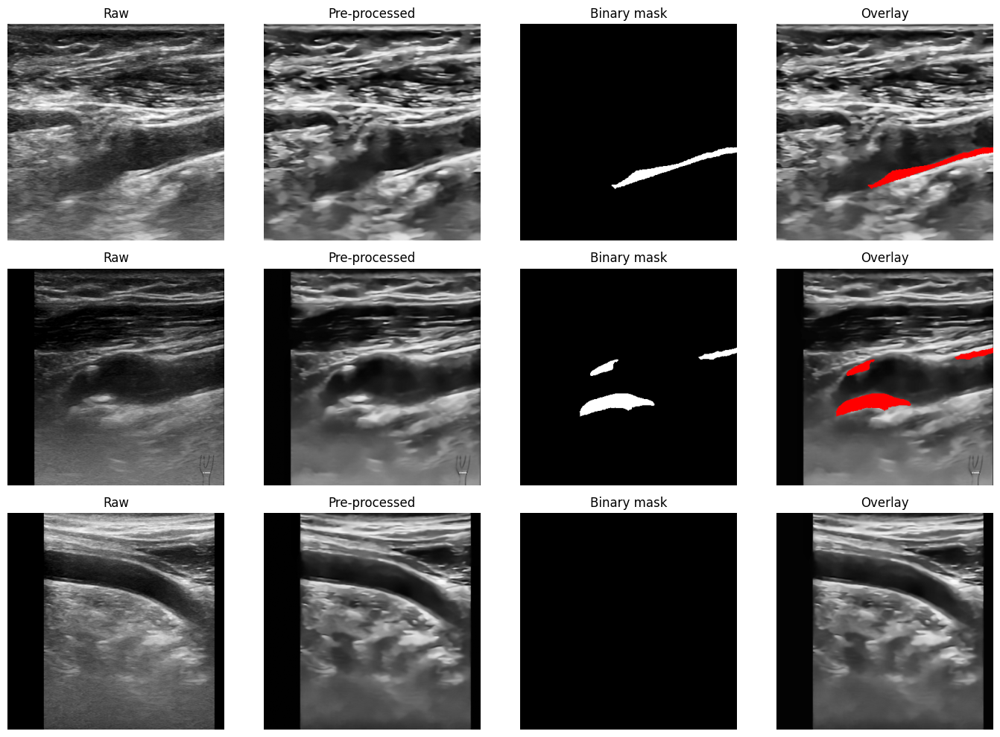

In [7]:
# quick visual sanity check: original vs. pre-processed image + mask overlay
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
sample_idx = np.random.choice(len(train_manifest), size=3, replace=False)
for row, i in enumerate(sample_idx):
    rec = train_manifest.iloc[i]
    orig = cv2.imread(rec.orig_image, cv2.IMREAD_GRAYSCALE)
    prep = cv2.imread(rec.prep_image, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(rec.prep_mask, cv2.IMREAD_GRAYSCALE)
    overlay = cv2.cvtColor(prep, cv2.COLOR_GRAY2BGR)
    overlay[mask > 127] = (0, 0, 255)
    axes[row, 0].imshow(orig, cmap="gray"); axes[row, 0].set_title("Raw"); axes[row, 0].axis("off")
    axes[row, 1].imshow(prep, cmap="gray"); axes[row, 1].set_title("Pre-processed"); axes[row, 1].axis("off")
    axes[row, 2].imshow(mask, cmap="gray"); axes[row, 2].set_title("Binary mask"); axes[row, 2].axis("off")
    axes[row, 3].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); axes[row, 3].set_title("Overlay"); axes[row, 3].axis("off")
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/preprocessing_samples.png", dpi=150)
plt.show()

## 3. PyTorch Dataset & augmentation

Images/masks are loaded from the cached pre-processed PNGs. Training-time
augmentation (horizontal flip, small rotations, brightness/contrast jitter, elastic / shift-scale-rotate
distortion, Gaussian noise) uses `albumentations` when available, with a minimal
NumPy/OpenCV fallback otherwise so the notebook still runs without that package.

In [8]:
def build_train_augmentation():
    if not HAS_ALBUMENTATIONS:
        return None
    try:
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.15, rotate_limit=12,
                               border_mode=cv2.BORDER_CONSTANT, p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
            A.RandomGamma(gamma_limit=(80, 120), p=0.3),
            A.ElasticTransform(alpha=30, sigma=5, p=0.2),
            A.GaussNoise(p=0.2),
        ])
    except Exception as e:                      # API differences between albumentations versions
        print("Falling back to the v1 augmentation pipeline:", e)
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
            A.GaussNoise(p=0.2),
        ])

def _fallback_augment(img, mask):
    if random.random() < 0.5:
        img, mask = np.fliplr(img).copy(), np.fliplr(mask).copy()
    if random.random() < 0.3:
        angle = random.uniform(-15, 15)
        h, w = img.shape
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), borderValue=0)
        mask = cv2.warpAffine(mask, M, (w, h), borderValue=0, flags=cv2.INTER_NEAREST)
    return img, mask

TRAIN_AUG = build_train_augmentation()

def compute_boundary_dist_map(mask01):
    '''Signed distance map used by the boundary loss (Kervadec et al., 2019).'''
    posmask = mask01.astype(bool)
    if posmask.any() and (~posmask).any():
        pos_dist = distance_transform_edt(posmask)
        neg_dist = distance_transform_edt(~posmask)
        dist = neg_dist * (~posmask) - (pos_dist - 1) * posmask
    else:
        dist = np.zeros_like(mask01, dtype=np.float32)
    return dist.astype(np.float32)

class PlaqueDataset(Dataset):
    def __init__(self, image_paths, mask_paths, augment=False, return_dist_map=False):
        self.image_paths = list(image_paths)
        self.mask_paths = list(mask_paths)
        self.augment = augment
        self.return_dist_map = return_dist_map

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(str(self.image_paths[idx]), cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(str(self.mask_paths[idx]), cv2.IMREAD_GRAYSCALE)
        mask01 = (mask > 127).astype(np.uint8)

        if self.augment:
            if TRAIN_AUG is not None:
                out = TRAIN_AUG(image=img, mask=mask01)
                img, mask01 = out["image"], out["mask"]
            else:
                img, mask01 = _fallback_augment(img, mask01)

        img_t = torch.from_numpy(img.astype(np.float32) / 255.0).unsqueeze(0)
        mask_t = torch.from_numpy(mask01.astype(np.float32)).unsqueeze(0)

        if self.return_dist_map:
            dist_t = torch.from_numpy(compute_boundary_dist_map(mask01)).unsqueeze(0)
            return img_t, mask_t, dist_t
        return img_t, mask_t

def paths_from_manifest(manifest_df):
    return manifest_df["prep_image"].tolist(), manifest_df["prep_mask"].tolist()

train_img_paths, train_mask_paths = paths_from_manifest(train_manifest)
test_img_paths, test_mask_paths = paths_from_manifest(test_manifest)

# which images contain plaque (used for stratified splitting)
has_plaque = np.array([cv2.imread(p, cv2.IMREAD_GRAYSCALE).max() > 127 for p in train_mask_paths])
test_has_plaque = np.array([cv2.imread(p, cv2.IMREAD_GRAYSCALE).max() > 127 for p in test_mask_paths])
print(f"{len(train_img_paths)} training images ({has_plaque.sum()} with plaque) / "
      f"{len(test_img_paths)} test images ({test_has_plaque.sum()} with plaque) ready.")

493 training images (316 with plaque) / 48 test images (24 with plaque) ready.


Batch shapes: torch.Size([4, 1, 384, 384]) torch.Size([4, 1, 384, 384]) torch.Size([4, 1, 384, 384])


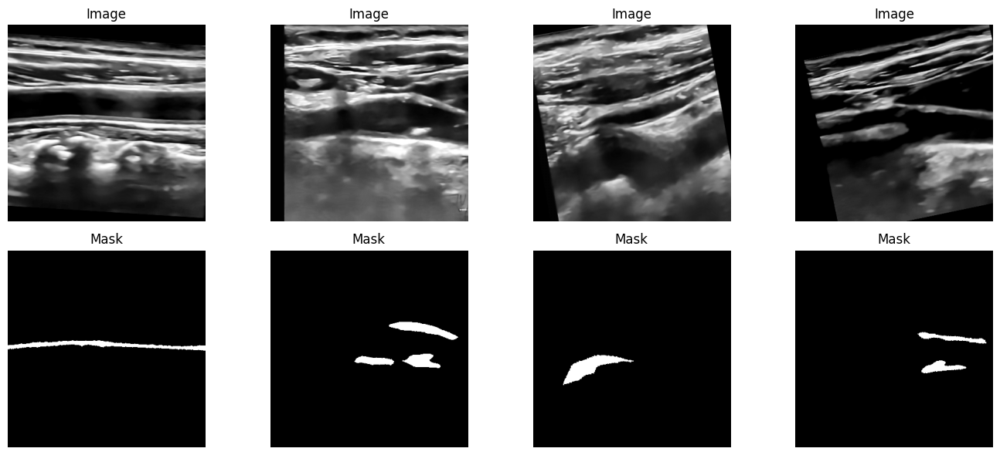

In [9]:
# quick sanity check on a training batch
_sanity_ds = PlaqueDataset(train_img_paths[:8], train_mask_paths[:8], augment=True, return_dist_map=True)
_loader = DataLoader(_sanity_ds, batch_size=4, shuffle=True)
imgs, masks, dists = next(iter(_loader))
print("Batch shapes:", imgs.shape, masks.shape, dists.shape)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i in range(4):
    axes[0, i].imshow(imgs[i, 0], cmap="gray"); axes[0, i].set_title("Image"); axes[0, i].axis("off")
    axes[1, i].imshow(masks[i, 0], cmap="gray"); axes[1, i].set_title("Mask"); axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/batch_sanity_check.png", dpi=150)
plt.show()

## 4. Proposed architecture — **FAB-UNet**

**F**requency-**A**ttentive, **B**oundary-aware U-Net. Building blocks:

* `SpectralAttention` — the novel component. Takes a feature map, computes its
  2-D real FFT (in float32, so it is safe under mixed precision), learns a small 1×1-conv gate over the concatenated (real, imag)
  channels, applies the gate, inverts the FFT, and adds a residual connection.
  This lets the network learn *which frequency bands* to keep or suppress —
  a natural fit for speckle-corrupted ultrasound.
* `SEResidualBlock` — residual convolutional block with squeeze-and-excitation
  channel recalibration.
* `AttentionGate` — Attention-U-Net-style gating applied to every skip connection.
* Bottleneck includes a Monte-Carlo-Dropout layer (`p = CFG.MC_DROPOUT_P`) that can
  be forced active at inference time (`mc_dropout=True`) to obtain epistemic
  uncertainty estimates without retraining or ensembling (Section 11).
* Two deep-supervision auxiliary heads at intermediate decoder scales.

A plain **baseline U-Net** (no attention, no spectral module, no deep supervision,
no boundary loss) of matching depth/width is also defined, purely so we can report
a fair proposed-vs-baseline comparison later in the notebook.
* `use_spectral=False` replaces every spectral block with an identity, so the ablation in Section 9 can measure what the novel block actually contributes.

In [10]:
class SpectralAttention(nn.Module):
    '''Learnable frequency-domain gating. The FFT is always computed in float32:
    half-precision cuFFT only supports power-of-2 sizes and 384/192/96/48/24 are not.'''
    def __init__(self, channels, reduction=4):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.gate = nn.Sequential(
            nn.Conv2d(channels * 2, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels * 2, kernel_size=1),
            nn.Sigmoid(),
        )
        self.last_gate = None  # cached for XAI visualisation

    def forward(self, x):
        dtype = x.dtype
        with torch.autocast(device_type="cuda", enabled=False):
            xf = x.float()
            fft = torch.fft.rfft2(xf, norm="ortho")
            real, imag = fft.real, fft.imag
            gate = self.gate(torch.cat([real, imag], dim=1))
            self.last_gate = gate.detach()
            g_real, g_imag = torch.chunk(gate, 2, dim=1)
            fft_gated = torch.complex(real * g_real, imag * g_imag)
            out = torch.fft.irfft2(fft_gated, s=xf.shape[-2:], norm="ortho") + xf
        return out.to(dtype)


class SEResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, se_reduction=8):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        hidden = max(out_ch // se_reduction, 4)
        self.se_fc = nn.Sequential(
            nn.Linear(out_ch, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, out_ch), nn.Sigmoid(),
        )

    def forward(self, x):
        identity = self.skip(x)
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        b, c, _, _ = out.shape
        se = self.se_fc(out.mean(dim=(2, 3))).view(b, c, 1, 1)
        out = out * se
        return F.relu(out + identity, inplace=True)


class AttentionGate(nn.Module):
    '''Oktay et al. (2018) style additive attention gate for skip connections.'''
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.w_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.BatchNorm2d(f_int))
        self.w_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.BatchNorm2d(f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())

    def forward(self, g, x):
        g1, x1 = self.w_g(g), self.w_x(x)
        alpha = self.psi(F.relu(g1 + x1, inplace=True))
        return x * alpha

In [11]:
class FABUNet(nn.Module):
    '''Frequency-Attentive, Boundary-aware U-Net with deep supervision and a
    built-in Monte-Carlo-Dropout bottleneck for epistemic uncertainty.'''

    def __init__(self, in_ch=1, base_ch=32, mc_dropout_p=0.3, use_spectral=True):
        super().__init__()
        c1, c2, c3, c4, c5 = base_ch, base_ch * 2, base_ch * 4, base_ch * 8, base_ch * 16
        Spec = SpectralAttention if use_spectral else (lambda c: nn.Identity())

        self.enc1 = SEResidualBlock(in_ch, c1)
        self.enc2 = SEResidualBlock(c1, c2)
        self.spec2 = Spec(c2)
        self.enc3 = SEResidualBlock(c2, c3)
        self.spec3 = Spec(c3)
        self.enc4 = SEResidualBlock(c3, c4)
        self.spec4 = Spec(c4)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = SEResidualBlock(c4, c5)
        self.spec5 = Spec(c5)
        self.mc_dropout_p = mc_dropout_p

        self.up4 = nn.ConvTranspose2d(c5, c4, 2, stride=2)
        self.ag4 = AttentionGate(c4, c4, c4 // 2)
        self.dec4 = SEResidualBlock(c4 * 2, c4)

        self.up3 = nn.ConvTranspose2d(c4, c3, 2, stride=2)
        self.ag3 = AttentionGate(c3, c3, c3 // 2)
        self.dec3 = SEResidualBlock(c3 * 2, c3)

        self.up2 = nn.ConvTranspose2d(c3, c2, 2, stride=2)
        self.ag2 = AttentionGate(c2, c2, c2 // 2)
        self.dec2 = SEResidualBlock(c2 * 2, c2)

        self.up1 = nn.ConvTranspose2d(c2, c1, 2, stride=2)
        self.ag1 = AttentionGate(c1, c1, c1 // 2)
        self.dec1 = SEResidualBlock(c1 * 2, c1)

        self.out_main = nn.Conv2d(c1, 1, 1)
        self.out_aux3 = nn.Conv2d(c3, 1, 1)   # deep supervision @ decoder stage 3
        self.out_aux2 = nn.Conv2d(c2, 1, 1)   # deep supervision @ decoder stage 2

    def forward(self, x, mc_dropout=False):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1)); e2 = self.spec2(e2)
        e3 = self.enc3(self.pool(e2)); e3 = self.spec3(e3)
        e4 = self.enc4(self.pool(e3)); e4 = self.spec4(e4)

        b = self.bottleneck(self.pool(e4)); b = self.spec5(b)
        b = F.dropout2d(b, p=self.mc_dropout_p, training=self.training or mc_dropout)

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([self.ag4(d4, e4), d4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([self.ag3(d3, e3), d3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([self.ag2(d2, e2), d2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([self.ag1(d1, e1), d1], dim=1))

        main = self.out_main(d1)
        aux3 = F.interpolate(self.out_aux3(d3), size=x.shape[-2:], mode="bilinear", align_corners=False)
        aux2 = F.interpolate(self.out_aux2(d2), size=x.shape[-2:], mode="bilinear", align_corners=False)
        return {"main": main, "aux3": aux3, "aux2": aux2}


class BaselineUNet(nn.Module):
    '''Plain encoder-decoder U-Net (no attention / spectral / deep supervision),
    used only as a fair comparison point to the proposed FAB-UNet.'''

    def __init__(self, in_ch=1, base_ch=32):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                  nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        c1, c2, c3, c4, c5 = base_ch, base_ch * 2, base_ch * 4, base_ch * 8, base_ch * 16
        self.enc1, self.enc2, self.enc3, self.enc4 = block(in_ch, c1), block(c1, c2), block(c2, c3), block(c3, c4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = block(c4, c5)
        self.up4, self.dec4 = nn.ConvTranspose2d(c5, c4, 2, 2), block(c4 * 2, c4)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, 2), block(c3 * 2, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, 2), block(c2 * 2, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, 2), block(c1 * 2, c1)
        self.out = nn.Conv2d(c1, 1, 1)

    def forward(self, x, mc_dropout=False):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return {"main": self.out(d1)}

_test_model = FABUNet().to(DEVICE)
_test_out = _test_model(torch.randn(2, 1, CFG.IMG_SIZE, CFG.IMG_SIZE).to(DEVICE))
print({k: v.shape for k, v in _test_out.items()})
n_params = sum(p.numel() for p in _test_model.parameters())
print(f"FAB-UNet parameters: {n_params:,}")
_b = BaselineUNet()
print(f"Baseline U-Net parameters: {sum(p.numel() for p in _b.parameters()):,}")
del _b
del _test_model, _test_out

{'main': torch.Size([2, 1, 384, 384]), 'aux3': torch.Size([2, 1, 384, 384]), 'aux2': torch.Size([2, 1, 384, 384])}
FAB-UNet parameters: 8,665,031
Baseline U-Net parameters: 7,765,409


## 5. Loss functions

`combined_loss` on the main output = **weighted BCE** (`pos_weight=5`, plaque is ~1% of pixels) + **batch Dice** + **Focal-Tversky** (`beta=0.7 > alpha=0.3`, favours recall) + an optional **boundary loss**. The boundary loss uses a distance map normalised per image and its weight is **ramped up** from 0 to `BND_MAX` over the first 40% of epochs (as in Kervadec et al.), so it does not dominate early training. Deep-supervision heads (FAB-UNet only) get lighter BCE + Dice terms.

Dice is computed over the whole batch instead of per image, because ~37% of the images have no plaque and a per-image Dice on an empty target is extremely noisy.

In [12]:
def dice_loss(logits, targets, eps=1.0):
    p = torch.sigmoid(logits.float()).reshape(-1)
    t = targets.float().reshape(-1)
    return 1 - (2 * (p * t).sum() + eps) / (p.sum() + t.sum() + eps)

def focal_tversky_loss(logits, targets, alpha=0.3, beta=0.7, gamma=0.75, eps=1.0):
    p = torch.sigmoid(logits.float()).reshape(-1)
    t = targets.float().reshape(-1)
    tp = (p * t).sum()
    fp = (p * (1 - t)).sum()
    fn = ((1 - p) * t).sum()
    tv = (tp + eps) / (tp + alpha * fp + beta * fn + eps)
    return (1 - tv) ** gamma

def boundary_loss(logits, dist_map):
    d = dist_map.float()
    d = d / (d.abs().amax(dim=(1, 2, 3), keepdim=True) + 1e-6)     # per-image normalisation to [-1, 1]
    return (torch.sigmoid(logits.float()) * d).mean()

BND_MAX = 1.0                 # final boundary-loss weight (tunable; ablated in Section 9)
BND_WEIGHT = {"w": 0.0}       # current weight, updated every epoch by train_one_fold
POS_WEIGHT = 5.0

def combined_loss(outputs, target, dist_map=None, w_bce=0.3, w_dice=0.3, w_ft=0.4):
    main = outputs["main"].float()
    target = target.float()
    pos_w = torch.tensor(POS_WEIGHT, device=main.device)
    loss = (w_bce * F.binary_cross_entropy_with_logits(main, target, pos_weight=pos_w)
            + w_dice * dice_loss(main, target)
            + w_ft * focal_tversky_loss(main, target))
    if dist_map is not None and BND_WEIGHT["w"] > 0:
        loss = loss + BND_WEIGHT["w"] * boundary_loss(main, dist_map)
    for key, w in (("aux3", 0.3), ("aux2", 0.2)):
        if key in outputs:
            aux = outputs[key].float()
            loss = loss + w * (F.binary_cross_entropy_with_logits(aux, target, pos_weight=pos_w)
                               + dice_loss(aux, target))
    return loss

## 6. Metrics — pixel-level confusion matrix, precision, recall, F1, Dice, IoU

Rather than concatenating every pixel of every image in memory (541 × 256 × 256 ≈
35M pixels), `ConfusionAccumulator` keeps running `TP / FP / TN / FN` counts and
derives every metric from those four numbers — exact and memory-light. v2 also reports **per-image Dice** (mean over images, and over plaque-containing images only), because pooled pixel Dice is dominated by images with large plaques and hides false positives on plaque-free images.

In [13]:
class ConfusionAccumulator:
    def __init__(self):
        self.tp = self.fp = self.tn = self.fn = 0

    def update(self, pred_bin, target_bin):
        pred_bin = pred_bin.astype(bool).ravel()
        target_bin = target_bin.astype(bool).ravel()
        self.tp += int(np.sum(pred_bin & target_bin))
        self.fp += int(np.sum(pred_bin & ~target_bin))
        self.fn += int(np.sum(~pred_bin & target_bin))
        self.tn += int(np.sum(~pred_bin & ~target_bin))

    def compute(self, eps=1e-9):
        precision = self.tp / (self.tp + self.fp + eps)
        recall = self.tp / (self.tp + self.fn + eps)
        f1 = 2 * precision * recall / (precision + recall + eps)
        iou = self.tp / (self.tp + self.fp + self.fn + eps)
        dice = 2 * self.tp / (2 * self.tp + self.fp + self.fn + eps)
        accuracy = (self.tp + self.tn) / (self.tp + self.tn + self.fp + self.fn + eps)
        specificity = self.tn / (self.tn + self.fp + eps)
        return dict(precision=precision, recall=recall, f1=f1, iou=iou, dice=dice,
                    accuracy=accuracy, specificity=specificity)

    def matrix(self):
        return np.array([[self.tn, self.fp], [self.fn, self.tp]])


def image_dice(pred, gt):
    s = pred.sum() + gt.sum()
    return 1.0 if s == 0 else 2.0 * (pred & gt).sum() / s


@torch.no_grad()
def evaluate_loader(model, loader, device, threshold=0.5, mc_dropout=False):
    model.eval()
    acc = ConfusionAccumulator()
    val_loss_total, n_batches = 0.0, 0
    img_dice, img_has = [], []
    for batch in loader:
        if len(batch) == 3:
            imgs, masks, dists = batch
            dists = dists.to(device)
        else:
            imgs, masks = batch
            dists = None
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = model(imgs, mc_dropout=mc_dropout)
        loss = combined_loss(outputs, masks, dists)
        val_loss_total += loss.item(); n_batches += 1
        probs = torch.sigmoid(outputs["main"].float()).cpu().numpy()
        preds = (probs > threshold)
        tgts = masks.cpu().numpy() > 0.5
        acc.update(preds, tgts)
        for p, t in zip(preds, tgts):
            img_dice.append(image_dice(p, t)); img_has.append(bool(t.any()))
    metrics = acc.compute()
    metrics["loss"] = val_loss_total / max(n_batches, 1)
    img_dice, img_has = np.array(img_dice), np.array(img_has)
    metrics["mean_image_dice"] = float(img_dice.mean())
    metrics["plaque_image_dice"] = float(img_dice[img_has].mean()) if img_has.any() else float("nan")
    return metrics, acc

## 7. Training utilities

AdamW, **linear warm-up (3 epochs) + cosine decay**, gradient clipping, automatic mixed precision, and early stopping / checkpoint selection on **validation Dice**. `use_boundary=False` turns the boundary term off, which is how the *fair* baseline and the ablation are trained.

In [14]:
class EarlyStopping:
    def __init__(self, patience=10, mode="min"):
        self.patience, self.mode = patience, mode
        self.best, self.count, self.should_stop = None, 0, False

    def step(self, value):
        better = (self.best is None or (self.mode == "min" and value < self.best)
                  or (self.mode == "max" and value > self.best))
        if better:
            self.best, self.count = value, 0
            return True
        self.count += 1
        if self.count >= self.patience:
            self.should_stop = True
        return False


def train_one_fold(model, train_loader, val_loader, device, epochs=CFG.EPOCHS, lr=CFG.LR,
                   patience=CFG.EARLY_STOP_PATIENCE, tag="fold", use_boundary=True, verbose=True):
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    warm = 3
    def lr_lambda(e):
        if e < warm:
            return (e + 1) / warm
        prog = (e - warm) / max(1, epochs - warm)
        return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
    stopper = EarlyStopping(patience=patience, mode="max")      # checkpoint on val Dice

    history = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": [], "val_f1": []}
    best_state, best_epoch = None, 0

    for epoch in range(1, epochs + 1):
        BND_WEIGHT["w"] = BND_MAX * min(1.0, epoch / (0.4 * epochs)) if use_boundary else 0.0
        model.train()
        running_loss, n_batches = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{tag}] epoch {epoch}/{epochs}", leave=False)
        for imgs, masks, dists in pbar:
            imgs, masks, dists = imgs.to(device), masks.to(device), dists.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                outputs = model(imgs)
            loss = combined_loss(outputs, masks, dists)          # losses are computed in float32
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item(); n_batches += 1
            pbar.set_postfix(loss=running_loss / n_batches)

        train_loss = running_loss / max(n_batches, 1)
        val_metrics, _ = evaluate_loader(model, val_loader, device)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_dice"].append(val_metrics["dice"])
        history["val_iou"].append(val_metrics["iou"])
        history["val_f1"].append(val_metrics["f1"])

        if stopper.step(val_metrics["dice"]):
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch

        if verbose and (epoch <= 3 or epoch % 5 == 0 or stopper.count == 0):
            print(f"[{tag}] epoch {epoch:03d} | lr {optimizer.param_groups[0]['lr']:.2e} | "
                  f"train_loss {train_loss:.4f} | val_loss {val_metrics['loss']:.4f} | "
                  f"val_dice {val_metrics['dice']:.4f} | val_iou {val_metrics['iou']:.4f}")

        if stopper.should_stop:
            print(f"[{tag}] Early stopping at epoch {epoch} (best val_dice={stopper.best:.4f} @ epoch {best_epoch})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    BND_WEIGHT["w"] = 0.0
    return model, history

## 8. Stratified K-fold cross-validation (k = 5)

FAB-UNet is trained from scratch on each of 5 **stratified** folds (stratified on plaque / no-plaque) of the **training** set. The 48-image test set is never touched here. The 5 fold checkpoints are kept: they form the **ensemble** evaluated in Section 10.

> Note: each fold's best checkpoint is selected on its own validation fold, so the CV numbers below are mildly optimistic. The out-of-fold predictions in Section 10 are used only to choose a threshold and a minimum component size, never the test set.


===== Fold 1/5 (train=394, val=99, val plaque imgs=64) =====


[fold1] epoch 1/120:   0%|          | 0/65 [00:00<?, ?it/s]

[fold1] epoch 001 | lr 6.67e-04 | train_loss 1.3707 | val_loss 1.2436 | val_dice 0.1551 | val_iou 0.0841


[fold1] epoch 2/120:   0%|          | 0/65 [00:00<?, ?it/s]

[fold1] epoch 002 | lr 1.00e-03 | train_loss 1.1084 | val_loss 1.1262 | val_dice 0.2916 | val_iou 0.1707


[fold1] epoch 3/120:   0%|          | 0/65 [00:00<?, ?it/s]

... (805 outputs left out)

[fold5] epoch 118/120:   0%|          | 0/65 [00:00<?, ?it/s]

[fold5] epoch 119/120:   0%|          | 0/65 [00:00<?, ?it/s]

[fold5] epoch 120/120:   0%|          | 0/65 [00:00<?, ?it/s]

[fold5] epoch 120 | lr 1.00e-05 | train_loss 0.3416 | val_loss 0.7630 | val_dice 0.6383 | val_iou 0.4687
[fold5] Early stopping at epoch 120 (best val_dice=0.6437 @ epoch 100)
[fold5] best-checkpoint val Dice = 0.6437 | IoU = 0.4746 | mean per-image Dice = 0.6285

K-fold cross-validation complete.


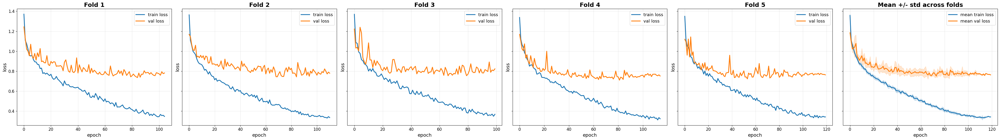

In [15]:
all_idx = np.arange(len(train_img_paths))
skf = StratifiedKFold(n_splits=CFG.K_FOLDS, shuffle=True, random_state=SEED)
fold_splits = list(skf.split(all_idx, has_plaque))

fold_histories, fold_metrics, fold_ckpt_paths = [], [], []

for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    print(f"\n===== Fold {fold + 1}/{CFG.K_FOLDS} (train={len(tr_idx)}, val={len(va_idx)}, "
          f"val plaque imgs={has_plaque[va_idx].sum()}) =====")
    set_seed(SEED + fold)

    tr_imgs = [train_img_paths[i] for i in tr_idx]; tr_masks = [train_mask_paths[i] for i in tr_idx]
    va_imgs = [train_img_paths[i] for i in va_idx]; va_masks = [train_mask_paths[i] for i in va_idx]

    train_ds = PlaqueDataset(tr_imgs, tr_masks, augment=True, return_dist_map=True)
    val_ds = PlaqueDataset(va_imgs, va_masks, augment=False, return_dist_map=True)
    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
                               num_workers=CFG.NUM_WORKERS, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=CFG.NUM_WORKERS)

    model = FABUNet(mc_dropout_p=CFG.MC_DROPOUT_P).to(DEVICE)
    model, history = train_one_fold(model, train_loader, val_loader, DEVICE,
                                     epochs=CFG.EPOCHS, tag=f"fold{fold+1}")

    val_metrics, _ = evaluate_loader(model, val_loader, DEVICE)
    fold_histories.append(history)
    fold_metrics.append(val_metrics)
    print(f"[fold{fold+1}] best-checkpoint val Dice = {val_metrics['dice']:.4f} | "
          f"IoU = {val_metrics['iou']:.4f} | mean per-image Dice = {val_metrics['mean_image_dice']:.4f}")

    ckpt_path = f"{CFG.OUTPUT_DIR}/fabunet_fold{fold+1}.pth"
    torch.save(model.state_dict(), ckpt_path)
    fold_ckpt_paths.append(ckpt_path)

    del model, train_loader, val_loader, train_ds, val_ds
    torch.cuda.empty_cache()

with open(f"{CFG.OUTPUT_DIR}/fold_histories.json", "w") as f:
    json.dump(fold_histories, f)
print("\nK-fold cross-validation complete.")# ---- per-fold train/val loss curves + combined mean +/- std curve ----
n_folds = len(fold_histories)

SUBPLOT_W, SUBPLOT_H = 7, 6   # size PER subplot (inches) -- increase these for even bigger plots

fig, axes = plt.subplots(1, n_folds + 1,
                          figsize=(SUBPLOT_W * (n_folds + 1), SUBPLOT_H),
                          sharey=True)

for i, hist in enumerate(fold_histories):
    axes[i].plot(hist["train_loss"], label="train loss", linewidth=2.5)
    axes[i].plot(hist["val_loss"], label="val loss", linewidth=2.5)
    axes[i].set_title(f"Fold {i + 1}", fontsize=18, fontweight="bold")
    axes[i].set_xlabel("epoch", fontsize=14)
    axes[i].set_ylabel("loss", fontsize=14)
    axes[i].tick_params(axis="both", labelsize=12)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=13)

max_len = max(len(h["train_loss"]) for h in fold_histories)
def pad(seq, length):
    arr = np.full(length, np.nan)
    arr[:len(seq)] = seq
    return arr

train_mat = np.stack([pad(h["train_loss"], max_len) for h in fold_histories])
val_mat = np.stack([pad(h["val_loss"], max_len) for h in fold_histories])

ax = axes[-1]
ax.plot(np.nanmean(train_mat, axis=0), label="mean train loss", color="C0", linewidth=2.5)
ax.fill_between(range(max_len), np.nanmean(train_mat, axis=0) - np.nanstd(train_mat, axis=0),
                 np.nanmean(train_mat, axis=0) + np.nanstd(train_mat, axis=0), alpha=0.2, color="C0")
ax.plot(np.nanmean(val_mat, axis=0), label="mean val loss", color="C1", linewidth=2.5)
ax.fill_between(range(max_len), np.nanmean(val_mat, axis=0) - np.nanstd(val_mat, axis=0),
                 np.nanmean(val_mat, axis=0) + np.nanstd(val_mat, axis=0), alpha=0.2, color="C1")
ax.set_title("Mean +/- std across folds", fontsize=18, fontweight="bold")
ax.set_xlabel("epoch", fontsize=14)
ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)
ax.legend(fontsize=13)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/kfold_loss_curves.png", dpi=150)
plt.show()

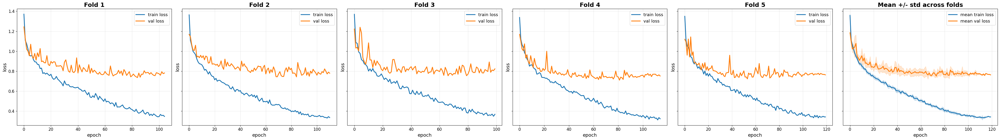

In [16]:
# ---- per-fold train/val loss curves + combined mean +/- std curve ----
n_folds = len(fold_histories)

SUBPLOT_W, SUBPLOT_H = 7, 6   # size PER subplot (inches) -- increase these for even bigger plots

fig, axes = plt.subplots(1, n_folds + 1,
                          figsize=(SUBPLOT_W * (n_folds + 1), SUBPLOT_H),
                          sharey=True)

for i, hist in enumerate(fold_histories):
    axes[i].plot(hist["train_loss"], label="train loss", linewidth=2.5)
    axes[i].plot(hist["val_loss"], label="val loss", linewidth=2.5)
    axes[i].set_title(f"Fold {i + 1}", fontsize=18, fontweight="bold")
    axes[i].set_xlabel("epoch", fontsize=14)
    axes[i].set_ylabel("loss", fontsize=14)
    axes[i].tick_params(axis="both", labelsize=12)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=13)

max_len = max(len(h["train_loss"]) for h in fold_histories)
def pad(seq, length):
    arr = np.full(length, np.nan)
    arr[:len(seq)] = seq
    return arr

train_mat = np.stack([pad(h["train_loss"], max_len) for h in fold_histories])
val_mat = np.stack([pad(h["val_loss"], max_len) for h in fold_histories])

ax = axes[-1]
ax.plot(np.nanmean(train_mat, axis=0), label="mean train loss", color="C0", linewidth=2.5)
ax.fill_between(range(max_len), np.nanmean(train_mat, axis=0) - np.nanstd(train_mat, axis=0),
                 np.nanmean(train_mat, axis=0) + np.nanstd(train_mat, axis=0), alpha=0.2, color="C0")
ax.plot(np.nanmean(val_mat, axis=0), label="mean val loss", color="C1", linewidth=2.5)
ax.fill_between(range(max_len), np.nanmean(val_mat, axis=0) - np.nanstd(val_mat, axis=0),
                 np.nanmean(val_mat, axis=0) + np.nanstd(val_mat, axis=0), alpha=0.2, color="C1")
ax.set_title("Mean +/- std across folds", fontsize=18, fontweight="bold")
ax.set_xlabel("epoch", fontsize=14)
ax.tick_params(axis="both", labelsize=12)
ax.grid(alpha=0.3)
ax.legend(fontsize=13)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/kfold_loss_curves.png", dpi=150)
plt.show()

In [17]:
# ---- k-fold summary table ----
cv_df = pd.DataFrame(fold_metrics)
cv_df.index = [f"fold_{i+1}" for i in range(len(fold_metrics))]
cv_df.loc["mean"] = cv_df.mean()
cv_df.loc["std"] = cv_df.loc[[f"fold_{i+1}" for i in range(len(fold_metrics))]].std()
cv_df = cv_df.round(4)
cv_df.to_csv(f"{CFG.OUTPUT_DIR}/kfold_cv_summary.csv")
cv_df

,precision,recall,f1,iou,dice,accuracy,specificity,loss,mean_image_dice,plaque_image_dice
fold_1,0.5783,0.6865,0.6278,0.4575,0.6278,0.9889,0.9931,0.7352,0.6300,0.5683
fold_2,0.5965,0.6028,0.5996,0.4282,0.5996,0.9912,0.9955,0.7794,0.6431,0.5027
fold_3,0.5643,0.6610,0.6089,0.4377,0.6089,0.9894,0.9935,0.7540,0.6336,0.5830
fold_4,0.6845,0.6404,0.6617,0.4944,0.6617,0.9916,0.9962,0.7471,0.6735,0.5556
fold_5,0.6088,0.6827,0.6437,0.4746,0.6437,0.9890,0.9935,0.7460,0.6285,0.5649
mean,0.6065,0.6547,0.6283,0.4585,0.6283,0.9900,0.9944,0.7524,0.6417,0.5549
std,0.0468,0.0344,0.0253,0.0269,0.0253,0.0013,0.0014,0.0166,0.0186,0.0308


## 9. Final single model, test-set evaluation, ROC / PR

A single FAB-UNet is trained on the full 493-image training set with a small **stratified** 10% hold-out used only for checkpoint selection. It is evaluated once on the untouched 48-image **test** set. (The stronger 5-fold ensemble comes in Section 10.)

In [18]:
set_seed(SEED)
final_tr_idx, final_va_idx = train_test_split(np.arange(len(train_img_paths)), test_size=0.1,
                                                random_state=SEED, shuffle=True, stratify=has_plaque)

final_tr_imgs = [train_img_paths[i] for i in final_tr_idx]; final_tr_masks = [train_mask_paths[i] for i in final_tr_idx]
final_va_imgs = [train_img_paths[i] for i in final_va_idx]; final_va_masks = [train_mask_paths[i] for i in final_va_idx]

final_train_ds = PlaqueDataset(final_tr_imgs, final_tr_masks, augment=True, return_dist_map=True)
final_val_ds = PlaqueDataset(final_va_imgs, final_va_masks, augment=False, return_dist_map=True)
final_train_loader = DataLoader(final_train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
                                  num_workers=CFG.NUM_WORKERS, drop_last=True)
final_val_loader = DataLoader(final_val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                                num_workers=CFG.NUM_WORKERS)

final_model = FABUNet(mc_dropout_p=CFG.MC_DROPOUT_P).to(DEVICE)
final_model, final_history = train_one_fold(final_model, final_train_loader, final_val_loader,
                                             DEVICE, epochs=CFG.EPOCHS, tag="final")

torch.save(final_model.state_dict(), f"{CFG.OUTPUT_DIR}/fabunet_final_best.pth")
print("Saved final FAB-UNet weights to", f"{CFG.OUTPUT_DIR}/fabunet_final_best.pth")

[final] epoch 1/120:   0%|          | 0/73 [00:00<?, ?it/s]

[final] epoch 001 | lr 6.67e-04 | train_loss 1.3551 | val_loss 1.0854 | val_dice 0.2602 | val_iou 0.1496


[final] epoch 2/120:   0%|          | 0/73 [00:00<?, ?it/s]

[final] epoch 002 | lr 1.00e-03 | train_loss 1.1126 | val_loss 1.1446 | val_dice 0.2513 | val_iou 0.1437


[final] epoch 3/120:   0%|          | 0/73 [00:00<?, ?it/s]

[final] epoch 003 | lr 1.00e-03 | train_loss 1.0634 | val_loss 1.0590 | val_dice 0.3032 | val_iou 0.1787


... (124 outputs left out)

[final] epoch 90/120:   0%|          | 0/73 [00:00<?, ?it/s]

[final] epoch 090 | lr 1.62e-04 | train_loss 0.3735 | val_loss 0.7692 | val_dice 0.5728 | val_iou 0.4013


[final] epoch 91/120:   0%|          | 0/73 [00:00<?, ?it/s]

[final] Early stopping at epoch 91 (best val_dice=0.5918 @ epoch 71)
Saved final FAB-UNet weights to /kaggle/working/outputs_v2/fabunet_final_best.pth


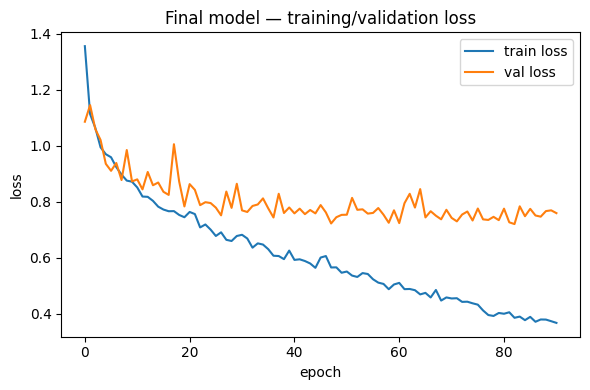

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(final_history["train_loss"], label="train loss")
plt.plot(final_history["val_loss"], label="val loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Final model — training/validation loss")
plt.legend(); plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/final_model_loss_curve.png", dpi=150)
plt.show()

Test-set metrics (FAB-UNet):
  precision   : 0.6073
  recall      : 0.6400
  f1          : 0.6232
  iou         : 0.4527
  dice        : 0.6232
  accuracy    : 0.9934
  specificity : 0.9964
  loss        : 0.8544
  mean_image_dice: 0.6750
  plaque_image_dice: 0.5584


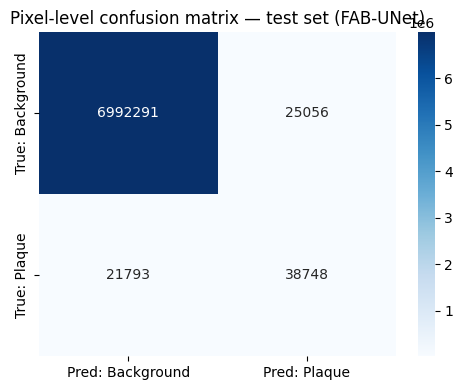

In [20]:
test_ds = PlaqueDataset(test_img_paths, test_mask_paths, augment=False, return_dist_map=True)
test_loader = DataLoader(test_ds, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS)

test_metrics, test_acc = evaluate_loader(final_model, test_loader, DEVICE)
print("Test-set metrics (FAB-UNet):")
for k, v in test_metrics.items():
    print(f"  {k:12s}: {v:.4f}")

cm = test_acc.matrix()
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Background", "Pred: Plaque"],
            yticklabels=["True: Background", "True: Plaque"])
plt.title("Pixel-level confusion matrix — test set (FAB-UNet)")
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/test_confusion_matrix.png", dpi=150)
plt.show()
np.savetxt(f"{CFG.OUTPUT_DIR}/test_confusion_matrix.csv", cm, fmt="%d", delimiter=",")

In [21]:
# ---- per-class precision / recall / F1 report (derived from the 2x2 confusion matrix) ----
tn, fp, fn, tp = test_acc.tn, test_acc.fp, test_acc.fn, test_acc.tp
eps = 1e-9

report = pd.DataFrame({
    "precision": [tn / (tn + fn + eps), tp / (tp + fp + eps)],
    "recall":    [tn / (tn + fp + eps), tp / (tp + fn + eps)],
    "support":   [tn + fp, tp + fn],
}, index=["background", "plaque"])
report["f1"] = 2 * report["precision"] * report["recall"] / (report["precision"] + report["recall"] + eps)
report.loc["macro avg"] = [report["precision"].mean(), report["recall"].mean(), report["support"].sum(), report["f1"].mean()]
w = report.loc[["background", "plaque"], "support"]
report.loc["weighted avg"] = [
    np.average(report.loc[["background", "plaque"], "precision"], weights=w),
    np.average(report.loc[["background", "plaque"], "recall"], weights=w),
    w.sum(),
    np.average(report.loc[["background", "plaque"], "f1"], weights=w),
]
report = report.round(4)
report.to_csv(f"{CFG.OUTPUT_DIR}/test_classification_report.csv")
report

,precision,recall,support,f1
background,0.9969,0.9964,7017347.0,0.9967
plaque,0.6073,0.6400,60541.0,0.6232
macro avg,0.8021,0.8182,7077888.0,0.8099
weighted avg,0.9936,0.9934,7077888.0,0.9935


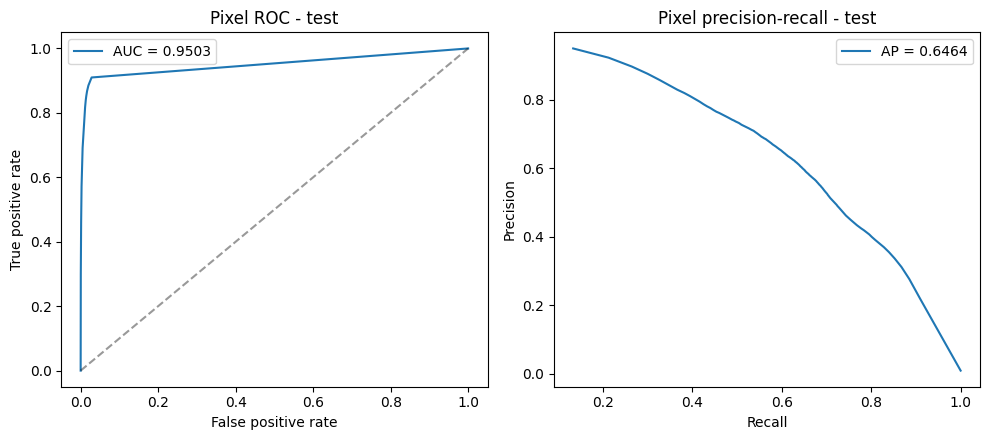

Test ROC-AUC: 0.9503 | Average precision (PR-AUC): 0.6464  (ROC-AUC is inflated by the ~99% easy background pixels; PR-AUC is the more informative number.)


In [22]:
# ---- pixel-level ROC and precision-recall curves, computed EXACTLY from probability histograms
# (v1 sub-sampled <1% of pixels with an unseeded RNG; this uses every test pixel)
@torch.no_grad()
def predict_probs(models, imgs, use_tta=True):
    '''imgs: (B,1,H,W) tensor on DEVICE -> (B,H,W) mean foreground probability
    over all models (and the horizontal-flip view if use_tta).'''
    acc, n = 0, 0
    for m in models:
        m.eval()
        views = [(imgs, lambda p: p)]
        if use_tta:
            views.append((torch.flip(imgs, dims=[3]), lambda p: torch.flip(p, dims=[3])))
        for x, inv in views:
            with torch.autocast(device_type="cuda", enabled=(DEVICE.type == "cuda")):
                p = torch.sigmoid(m(x)["main"].float())
            acc = acc + inv(p); n += 1
    return (acc / n)[:, 0]


def collect_probs(models, img_paths, mask_paths, use_tta=True, batch=8):
    probs, gts = [], []
    for s in range(0, len(img_paths), batch):
        ims = [cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) for p in img_paths[s:s + batch]]
        x = torch.from_numpy(np.stack(ims).astype(np.float32) / 255.0)[:, None].to(DEVICE)
        probs += list(predict_probs(models, x, use_tta).cpu().numpy())
        gts += [cv2.imread(str(m), cv2.IMREAD_GRAYSCALE) > 127 for m in mask_paths[s:s + batch]]
    return probs, gts


def roc_pr_from_hist(probs, gts, n_bins=2000):
    edges = np.linspace(0, 1, n_bins + 1)
    pos = np.zeros(n_bins); neg = np.zeros(n_bins)
    for p, g in zip(probs, gts):
        pos += np.histogram(p[g], bins=edges)[0]
        neg += np.histogram(p[~g], bins=edges)[0]
    tp = np.cumsum(pos[::-1]); fp = np.cumsum(neg[::-1])          # threshold sweeps high -> low
    tpr = np.r_[0, tp / pos.sum()]; fpr = np.r_[0, fp / neg.sum()]
    prec = tp / np.maximum(tp + fp, 1); rec = tp / pos.sum()
    _trapz = getattr(np, "trapezoid", None) or np.trapz
    roc_auc = float(_trapz(tpr, fpr))
    ap = float(np.sum(np.diff(np.r_[0, rec]) * prec))
    return fpr, tpr, rec, prec, roc_auc, ap

single_probs, test_gts = collect_probs([final_model], test_img_paths, test_mask_paths, use_tta=False)
fpr, tpr, rec_c, prec_c, roc_auc, ap = roc_pr_from_hist(single_probs, test_gts)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}"); ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("Pixel ROC - test"); ax[0].legend()
ax[1].plot(rec_c, prec_c, label=f"AP = {ap:.4f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Pixel precision-recall - test"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{CFG.OUTPUT_DIR}/test_roc_pr_curves.png", dpi=150); plt.show()
print(f"Test ROC-AUC: {roc_auc:.4f} | Average precision (PR-AUC): {ap:.4f}  "
      "(ROC-AUC is inflated by the ~99% easy background pixels; PR-AUC is the more informative number.)")

## 10. Fold-ensemble + flip test-time augmentation + out-of-fold-tuned post-processing

1. **Out-of-fold (OOF) predictions**: every training image is predicted by the fold model that did *not* train on it (with flip TTA).
2. The **probability threshold** and a **minimum connected-component size** (removes tiny false-positive blobs) are tuned on the OOF predictions only.
3. The **5-model ensemble + flip TTA** with those settings is applied **once** to the test set.

No test-set information is used to choose any setting.

In [23]:
from scipy import ndimage as ndi

def postprocess(prob, thr=0.5, min_px=0):
    b = prob > thr
    if min_px > 0 and b.any():
        lab, n = ndi.label(b)
        sizes = np.bincount(lab.ravel())
        small = sizes < min_px
        small[0] = False
        b = b & ~small[lab]
    return b

def counts_from(preds, gts):
    '''per-image [TP, FP, FN] array'''
    return np.array([[(p & g).sum(), (p & ~g).sum(), (~p & g).sum()] for p, g in zip(preds, gts)], dtype=np.int64)

def pooled_dice(c):
    tp, fp, fn = c.sum(axis=0)
    return 2.0 * tp / (2 * tp + fp + fn + 1e-9)

def per_image_dices(preds, gts):
    return np.array([image_dice(p, g) for p, g in zip(preds, gts)])

def bootstrap_ci(c, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(c), size=(n_boot, len(c)))
    tp, fp, fn = (c[:, k][idx].sum(axis=1) for k in range(3))
    d = 2.0 * tp / (2 * tp + fp + fn + 1e-9)
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

def bootstrap_diff(c_a, c_b, n_boot=2000, seed=0):
    '''paired bootstrap of pooled-Dice(A) - pooled-Dice(B) over test images'''
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(c_a), size=(n_boot, len(c_a)))
    def d(c):
        tp, fp, fn = (c[:, k][idx].sum(axis=1) for k in range(3))
        return 2.0 * tp / (2 * tp + fp + fn + 1e-9)
    diff = d(c_a) - d(c_b)
    return float(diff.mean()), float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5)), float((diff <= 0).mean())

# ---- 1) out-of-fold probabilities (each image predicted by the model that never saw it)
oof_probs = [None] * len(train_img_paths)
oof_gts = [None] * len(train_img_paths)
for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    m = FABUNet(mc_dropout_p=CFG.MC_DROPOUT_P).to(DEVICE)
    m.load_state_dict(torch.load(fold_ckpt_paths[fold], map_location=DEVICE)); m.eval()
    p, g = collect_probs([m], [train_img_paths[i] for i in va_idx], [train_mask_paths[i] for i in va_idx], use_tta=True)
    for j, i in enumerate(va_idx):
        oof_probs[i], oof_gts[i] = p[j], g[j]
    del m; torch.cuda.empty_cache()

# ---- 2) tune threshold / min component size on OOF only
grid = []
for thr in np.arange(0.30, 0.76, 0.05):
    for mp in (0, 50, 150, 300, 600):
        preds = [postprocess(p, thr, mp) for p in oof_probs]
        grid.append((pooled_dice(counts_from(preds, oof_gts)), float(thr), mp))
grid.sort(reverse=True)
best_oof_dice, BEST_THR, BEST_MIN_PX = grid[0]
oof_default = pooled_dice(counts_from([p > 0.5 for p in oof_probs], oof_gts))
print(f"OOF Dice @ thr 0.50, no post-proc : {oof_default:.4f}")
print(f"OOF Dice @ tuned (thr={BEST_THR:.2f}, min_px={BEST_MIN_PX}) : {best_oof_dice:.4f}")

# ---- 3) apply ONCE to the untouched test set with the 5-model ensemble
ens_models = []
for path in fold_ckpt_paths:
    m = FABUNet(mc_dropout_p=CFG.MC_DROPOUT_P).to(DEVICE)
    m.load_state_dict(torch.load(path, map_location=DEVICE)); ens_models.append(m.eval())

ens_probs, test_gts = collect_probs(ens_models, test_img_paths, test_mask_paths, use_tta=True)
ens_raw_preds = [p > 0.5 for p in ens_probs]
ens_pp_preds = [postprocess(p, BEST_THR, BEST_MIN_PX) for p in ens_probs]

single_preds = [p > 0.5 for p in single_probs]
rows = {}
for name, preds in [("FAB-UNet single model @0.5", single_preds),
                    ("FAB-UNet 5-fold ensemble + TTA @0.5", ens_raw_preds),
                    ("FAB-UNet ensemble + TTA + tuned post-proc", ens_pp_preds)]:
    c = counts_from(preds, test_gts)
    lo, hi = bootstrap_ci(c)
    pid = per_image_dices(preds, test_gts)
    rows[name] = dict(pooled_dice=pooled_dice(c), ci_low=lo, ci_high=hi,
                      mean_image_dice=pid.mean(), plaque_image_dice=pid[test_has_plaque].mean(),
                      counts=c)
ens_table = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "counts"} for k, v in rows.items()}).T.round(4)
ens_table.to_csv(f"{CFG.OUTPUT_DIR}/test_ensemble_results.csv")
ens_table

OOF Dice @ thr 0.50, no post-proc : 0.6326
OOF Dice @ tuned (thr=0.45, min_px=600) : 0.6342


,pooled_dice,ci_low,ci_high,mean_image_dice,plaque_image_dice
FAB-UNet single model @0.5,0.6233,0.5302,0.6993,0.6751,0.5585
FAB-UNet 5-fold ensemble + TTA @0.5,0.6522,0.5559,0.7290,0.7558,0.5949
FAB-UNet ensemble + TTA + tuned post-proc,0.6525,0.5464,0.7384,0.7643,0.5702


## 11. Fair baseline U-Net and (optional) ablations

The baseline is the plain U-Net (no SE blocks, attention gates, spectral blocks or deep supervision) trained on the **same** split, **same** loss terms (BCE + Dice + Focal-Tversky) and the same schedule, but **without the boundary loss** (`use_boundary=False`), which is what v1's text claimed but its code did not do.

Set `RUN_ABLATIONS = True` to additionally train *FAB-UNet without boundary loss* and *FAB-UNet without spectral attention*. These show what each novel component actually contributes (roughly 2 extra training runs).

In [24]:
set_seed(SEED)
baseline_model = BaselineUNet().to(DEVICE)
baseline_model, baseline_history = train_one_fold(
    baseline_model, final_train_loader, final_val_loader, DEVICE,
    epochs=CFG.EPOCHS, tag="baseline", use_boundary=False
)
torch.save(baseline_model.state_dict(), f"{CFG.OUTPUT_DIR}/baseline_unet_final.pth")

baseline_test_metrics, baseline_test_acc = evaluate_loader(baseline_model, test_loader, DEVICE)
print("Baseline U-Net test metrics:", {k: round(v, 4) for k, v in baseline_test_metrics.items()})

[baseline] epoch 1/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] epoch 001 | lr 6.67e-04 | train_loss 0.8352 | val_loss 0.8097 | val_dice 0.0000 | val_iou 0.0000


[baseline] epoch 2/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] epoch 002 | lr 1.00e-03 | train_loss 0.7881 | val_loss 0.7705 | val_dice 0.1274 | val_iou 0.0681


[baseline] epoch 3/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] epoch 003 | lr 1.00e-03 | train_loss 0.7408 | val_loss 0.7503 | val_dice 0.0000 | val_iou 0.0000


... (115 outputs left out)

[baseline] epoch 81/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] epoch 82/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] epoch 83/120:   0%|          | 0/73 [00:00<?, ?it/s]

[baseline] Early stopping at epoch 83 (best val_dice=0.5472 @ epoch 63)
Baseline U-Net test metrics: {'precision': 0.4867, 'recall': 0.6424, 'f1': 0.5538, 'iou': 0.3829, 'dice': 0.5538, 'accuracy': 0.9911, 'specificity': 0.9942, 'loss': 0.5135, 'mean_image_dice': 0.4532, 'plaque_image_dice': 0.5313}


In [25]:
RUN_ABLATIONS = False        # <-- set True to train the two ablation models

ablation_probs = {}
if RUN_ABLATIONS:
    for name, model_kwargs, tb in [("FAB-UNet w/o boundary loss", dict(), False),
                                    ("FAB-UNet w/o spectral attention", dict(use_spectral=False), True)]:
        set_seed(SEED)
        m = FABUNet(mc_dropout_p=CFG.MC_DROPOUT_P, **model_kwargs).to(DEVICE)
        m, _ = train_one_fold(m, final_train_loader, final_val_loader, DEVICE,
                              epochs=CFG.EPOCHS, tag=name.replace(" ", "_")[:18], use_boundary=tb)
        ablation_probs[name], _ = collect_probs([m], test_img_paths, test_mask_paths, use_tta=False)
        del m; torch.cuda.empty_cache()
else:
    print("Ablations skipped (RUN_ABLATIONS = False).")

Ablations skipped (RUN_ABLATIONS = False).


### Comparison with bootstrap confidence intervals

All rows are evaluated on the same 48 test images. Intervals are 95% percentile bootstrap CIs over **test images**. With only 48 images these are wide, so a gap smaller than the interval should not be claimed as an improvement. The paired-difference line reports the probability that the proposed model is *not* better than the baseline.

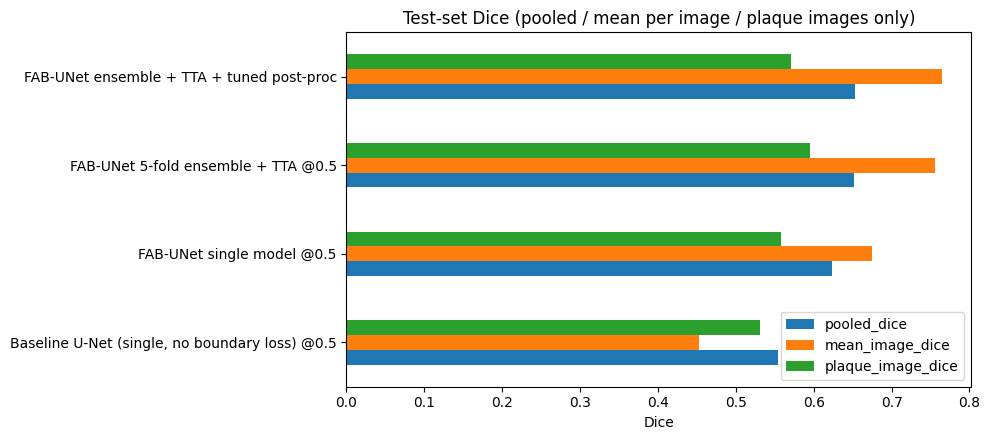

Paired bootstrap, FAB-UNet single - Baseline (pooled Dice): +0.0708  95% CI [-0.0025, +0.1434]  P(not better) = 0.029
Paired bootstrap, Ensemble+TTA+PP - FAB-UNet single       : +0.0293  95% CI [-0.0105, +0.0674]  P(not better) = 0.069
NOTE: the ensemble uses 5 models trained on 80% of the data each, the single models use 1 model; the ensemble-vs-baseline gap therefore mixes architecture and ensembling effects.


,pooled_dice,CI_95,precision,recall,mean_image_dice,plaque_image_dice
"Baseline U-Net (single, no boundary loss) @0.5",0.553879,"[0.454, 0.631]",0.486842,0.642325,0.453228,0.531455
FAB-UNet single model @0.5,0.623292,"[0.530, 0.699]",0.607363,0.640079,0.675082,0.558496
FAB-UNet 5-fold ensemble + TTA @0.5,0.652163,"[0.556, 0.729]",0.663753,0.640971,0.755761,0.594856
FAB-UNet ensemble + TTA + tuned post-proc,0.652463,"[0.546, 0.738]",0.673938,0.632315,0.764284,0.570235


In [26]:
base_probs, _ = collect_probs([baseline_model], test_img_paths, test_mask_paths, use_tta=False)
base_preds = [p > 0.5 for p in base_probs]

comp = {"Baseline U-Net (single, no boundary loss) @0.5": base_preds,
        "FAB-UNet single model @0.5": single_preds}
for name, pr in ablation_probs.items():
    comp[name + " @0.5"] = [p > 0.5 for p in pr]
comp["FAB-UNet 5-fold ensemble + TTA @0.5"] = ens_raw_preds
comp["FAB-UNet ensemble + TTA + tuned post-proc"] = ens_pp_preds

cmp_rows, cmp_counts = {}, {}
for name, preds in comp.items():
    c = counts_from(preds, test_gts); cmp_counts[name] = c
    lo, hi = bootstrap_ci(c); pid = per_image_dices(preds, test_gts)
    tp, fp, fn = c.sum(axis=0)
    cmp_rows[name] = dict(pooled_dice=pooled_dice(c), CI_95=f"[{lo:.3f}, {hi:.3f}]",
                          precision=tp / (tp + fp + 1e-9), recall=tp / (tp + fn + 1e-9),
                          mean_image_dice=pid.mean(), plaque_image_dice=pid[test_has_plaque].mean())
compare_df = pd.DataFrame(cmp_rows).T
compare_df.to_csv(f"{CFG.OUTPUT_DIR}/baseline_vs_proposed.csv")

ax = compare_df[["pooled_dice", "mean_image_dice", "plaque_image_dice"]].astype(float).plot(kind="barh", figsize=(10, 4.5))
ax.set_title("Test-set Dice (pooled / mean per image / plaque images only)"); ax.set_xlabel("Dice")
plt.tight_layout(); plt.savefig(f"{CFG.OUTPUT_DIR}/baseline_vs_proposed.png", dpi=150); plt.show()

d, lo, hi, p_nb = bootstrap_diff(cmp_counts["FAB-UNet single model @0.5"],
                                 cmp_counts["Baseline U-Net (single, no boundary loss) @0.5"])
print(f"Paired bootstrap, FAB-UNet single - Baseline (pooled Dice): {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  "
      f"P(not better) = {p_nb:.3f}")
d, lo, hi, p_nb = bootstrap_diff(cmp_counts["FAB-UNet ensemble + TTA + tuned post-proc"],
                                 cmp_counts["FAB-UNet single model @0.5"])
print(f"Paired bootstrap, Ensemble+TTA+PP - FAB-UNet single       : {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  "
      f"P(not better) = {p_nb:.3f}")
print("NOTE: the ensemble uses 5 models trained on 80% of the data each, the single models use 1 model; "
      "the ensemble-vs-baseline gap therefore mixes architecture and ensembling effects.")
compare_df.round(4)

## Qualitative results on the test set (ensemble + TTA + tuned post-processing)

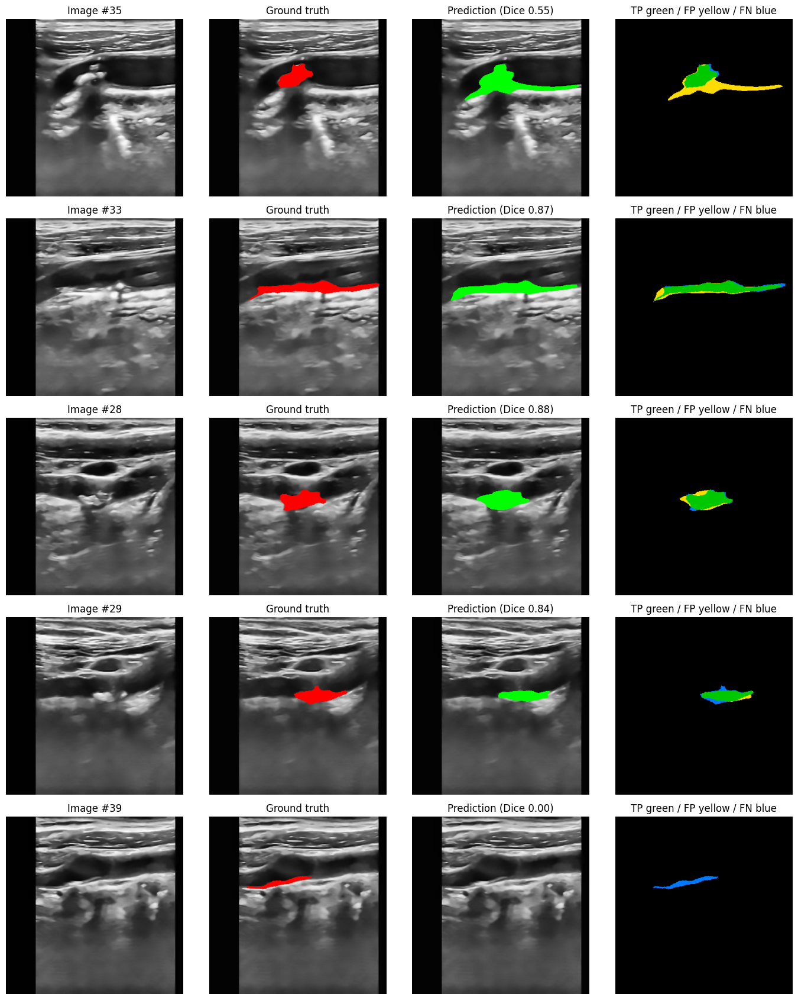

Lowest per-image Dice on the test set: [(26, 0.0, True), (16, 0.0, False), (43, 0.0, True), (39, 0.0, True), (44, 0.0, True)] (index, Dice, has_plaque)
Plaque-free test images with predicted plaque pixels (index, #px): [(np.int64(16), 782)]


In [27]:
rng_q = np.random.default_rng(0)
plaque_idx = np.where(test_has_plaque)[0]
show_idx = rng_q.choice(plaque_idx, size=min(5, len(plaque_idx)), replace=False)

fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))
axes = np.atleast_2d(axes)
for row, idx in enumerate(show_idx):
    img = cv2.imread(str(test_img_paths[idx]), cv2.IMREAD_GRAYSCALE)
    gt_bin = test_gts[idx].astype(np.uint8)
    pred_bin = ens_pp_preds[idx].astype(np.uint8)

    err = np.zeros((*img.shape, 3), dtype=np.uint8)
    err[(pred_bin == 1) & (gt_bin == 0)] = (255, 220, 0)   # FP yellow
    err[(pred_bin == 0) & (gt_bin == 1)] = (0, 120, 255)   # FN blue
    err[(pred_bin == 1) & (gt_bin == 1)] = (0, 200, 0)     # TP green
    gt_ov = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR); gt_ov[gt_bin == 1] = (0, 0, 255)
    pr_ov = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR); pr_ov[pred_bin == 1] = (0, 255, 0)

    d = image_dice(ens_pp_preds[idx], test_gts[idx])
    axes[row, 0].imshow(img, cmap="gray"); axes[row, 0].set_title(f"Image #{idx}")
    axes[row, 1].imshow(cv2.cvtColor(gt_ov, cv2.COLOR_BGR2RGB)); axes[row, 1].set_title("Ground truth")
    axes[row, 2].imshow(cv2.cvtColor(pr_ov, cv2.COLOR_BGR2RGB)); axes[row, 2].set_title(f"Prediction (Dice {d:.2f})")
    axes[row, 3].imshow(err); axes[row, 3].set_title("TP green / FP yellow / FN blue")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{CFG.OUTPUT_DIR}/qualitative_results.png", dpi=150); plt.show()

# worst cases are the most informative
pid_ens = per_image_dices(ens_pp_preds, test_gts)
worst = np.argsort(pid_ens)[:5]
print("Lowest per-image Dice on the test set:", [(int(i), round(float(pid_ens[i]), 3), bool(test_has_plaque[i])) for i in worst],
      "(index, Dice, has_plaque)")
fp_free = [(i, int(ens_pp_preds[i].sum())) for i in np.where(~test_has_plaque)[0]]
print("Plaque-free test images with predicted plaque pixels (index, #px):", [t for t in fp_free if t[1] > 0])

## 12. Explainable AI

Three complementary XAI views, each tied to a different part of FAB-UNet:

1. **Seg-Grad-CAM** — gradient-weighted class-activation mapping adapted to
   segmentation (Vinogradova et al., 2020): the gradient of the
   *foreground logit summed over the predicted plaque region* with respect to the last encoder block's activations
   is used to produce a coarse localisation heatmap, showing which image regions
   most influenced the plaque prediction.
2. **Learned spectral-attention maps** — visualises the frequency-domain gate
   learned inside `SpectralAttention`, i.e. which frequency bands the network
   chose to amplify or suppress for a given image (directly interprets the novel
   architectural component).
3. **Monte-Carlo-Dropout epistemic uncertainty** — `CFG.MC_SAMPLES` stochastic
   forward passes (dropout forced active at inference) give a pixel-wise mean
   prediction and variance. v2 evaluates, on the **whole test set**, how well this
   variance ranks erroneous pixels (AUROC) and compares it with plain predictive
   entropy, to test whether MC-Dropout adds anything over a deterministic model.

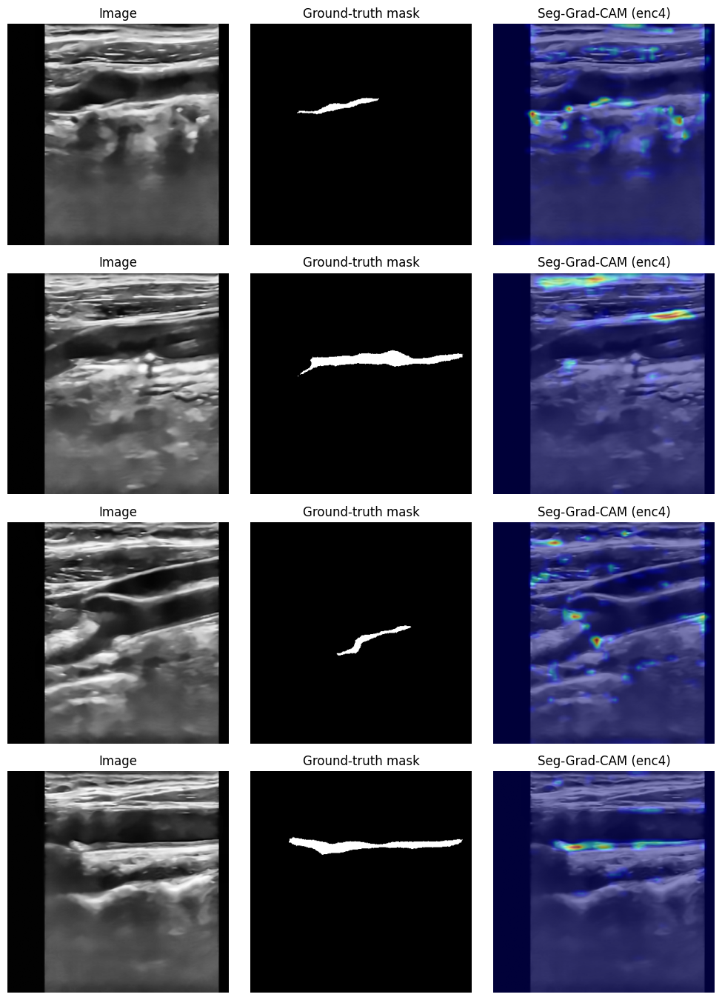

In [28]:
class SegGradCAM:
    '''Seg-Grad-CAM on a chosen layer. The score is the logit summed over the predicted
    plaque region (falls back to the 200 most confident pixels if nothing is predicted).
    Gradients are captured with tensor hooks, and the forward hook can be removed afterwards.'''
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model, None, None
        self._h = layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.act = out
        out.register_hook(lambda g: setattr(self, "grad", g))

    def remove(self):
        self._h.remove()

    def __call__(self, x):
        self.model.eval(); self.model.zero_grad()
        logits = self.model(x)["main"]
        prob = torch.sigmoid(logits)
        region = (prob > 0.5).float()
        if region.sum() == 0:
            kth = prob.flatten().topk(200).values[-1]
            region = (prob >= kth).float()
        (logits * region).sum().backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

gradcam = SegGradCAM(final_model, final_model.enc4)
rng_x = np.random.default_rng(1)
show_idx = rng_x.choice(np.where(test_has_plaque)[0], size=4, replace=False)

fig, axes = plt.subplots(len(show_idx), 3, figsize=(10, 3.4 * len(show_idx)))
for row, idx in enumerate(show_idx):
    img = cv2.imread(str(test_img_paths[idx]), cv2.IMREAD_GRAYSCALE)
    img_t = torch.from_numpy(img.astype(np.float32) / 255.0)[None, None].to(DEVICE)
    cam = gradcam(img_t)
    axes[row, 0].imshow(img, cmap="gray"); axes[row, 0].set_title("Image")
    axes[row, 1].imshow(test_gts[idx], cmap="gray"); axes[row, 1].set_title("Ground-truth mask")
    axes[row, 2].imshow(img, cmap="gray"); axes[row, 2].imshow(cam, cmap="jet", alpha=0.45); axes[row, 2].set_title("Seg-Grad-CAM (enc4)")
    for a in axes[row]: a.axis("off")
gradcam.remove()
plt.tight_layout(); plt.savefig(f"{CFG.OUTPUT_DIR}/seg_gradcam.png", dpi=150); plt.show()

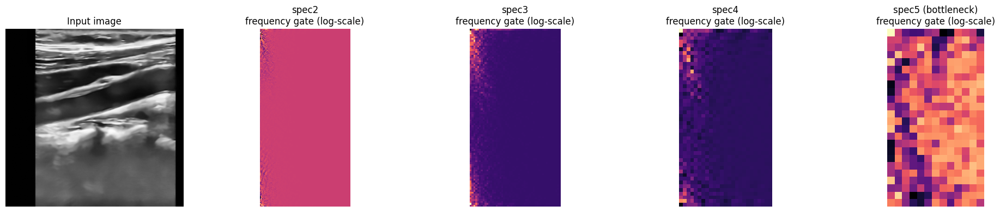

Low spatial-frequency-index regions of this plot correspond to coarse/global frequency components; brighter regions indicate frequency bands the network chose to amplify for this image.


In [29]:
# ---- learned spectral-attention map for a sample image ----
final_model.eval()
sample_idx = int(np.where(test_has_plaque)[0][0])
img = cv2.imread(str(test_img_paths[sample_idx]), cv2.IMREAD_GRAYSCALE)
img_t = torch.from_numpy(img.astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    _ = final_model(img_t)

spectral_modules = {"spec2": final_model.spec2, "spec3": final_model.spec3,
                     "spec4": final_model.spec4, "spec5 (bottleneck)": final_model.spec5}

fig, axes = plt.subplots(1, len(spectral_modules) + 1, figsize=(4 * (len(spectral_modules) + 1), 4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("Input image"); axes[0].axis("off")

for i, (name, mod) in enumerate(spectral_modules.items(), start=1):
    gate = mod.last_gate  # (1, 2*C, Hf, Wf) sigmoid gate values in frequency domain
    gate_mag = gate.mean(dim=1)[0].cpu().numpy()  # average across (real/imag, channel) gates
    axes[i].imshow(np.log1p(gate_mag), cmap="magma")
    axes[i].set_title(f"{name}\nfrequency gate (log-scale)")
    axes[i].axis("off")

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/spectral_attention_maps.png", dpi=150)
plt.show()
print("Low spatial-frequency-index regions of this plot correspond to coarse/global "
      "frequency components; brighter regions indicate frequency bands the network "
      "chose to amplify for this image.")

AUROC for detecting wrong pixels, whole test set:
  MC-Dropout variance (10 samples) : 0.981
  Predictive entropy of the mean prediction     : 0.982
If the two are close, MC-Dropout adds little beyond what the (cheaper) softmax uncertainty already tells you; both are largely high near plaque boundaries, where errors concentrate.


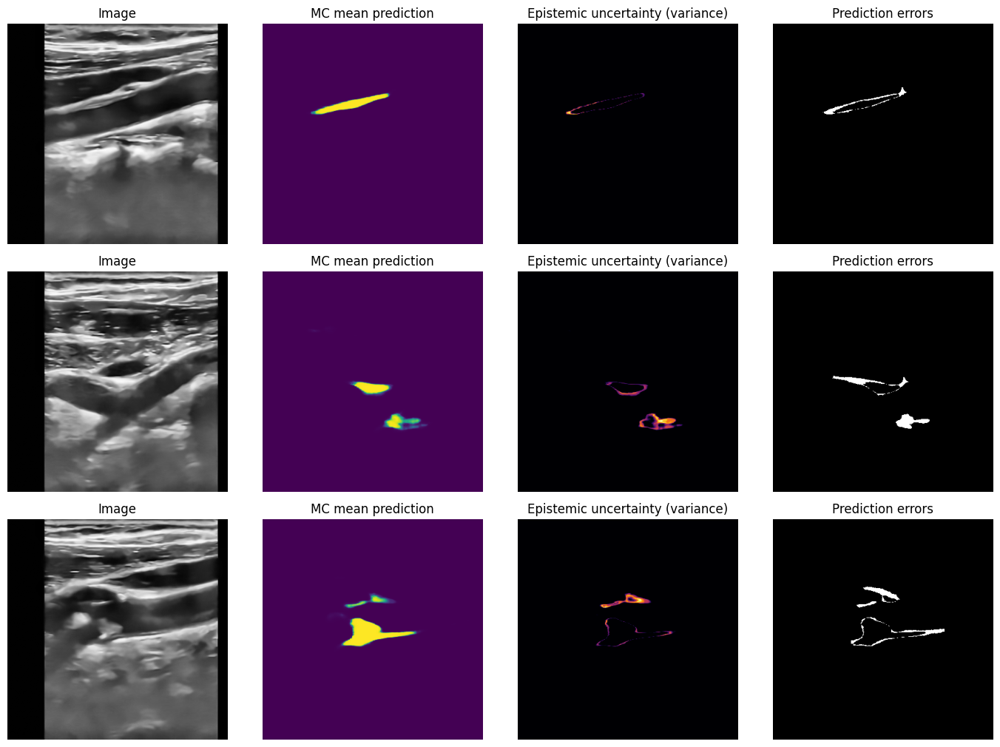

In [30]:
# ---- Monte-Carlo-Dropout epistemic uncertainty, evaluated on the WHOLE test set
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def mc_dropout_predict(model, img_t, n_samples=CFG.MC_SAMPLES):
    model.eval()
    probs = np.stack([torch.sigmoid(model(img_t, mc_dropout=True)["main"].float())[0, 0].cpu().numpy()
                      for _ in range(n_samples)])
    return probs.mean(axis=0), probs.var(axis=0)

rng_u = np.random.default_rng(0)
unc_var, unc_ent, err_flag = [], [], []
mc_cache = {}
for idx in range(len(test_img_paths)):
    img = cv2.imread(str(test_img_paths[idx]), cv2.IMREAD_GRAYSCALE)
    x = torch.from_numpy(img.astype(np.float32) / 255.0)[None, None].to(DEVICE)
    mean_p, var_p = mc_dropout_predict(final_model, x)
    mc_cache[idx] = (mean_p, var_p)
    err = ((mean_p > 0.5) != test_gts[idx]).ravel()
    ent = -(mean_p * np.log(mean_p + 1e-8) + (1 - mean_p) * np.log(1 - mean_p + 1e-8)).ravel()
    # keep every error pixel + a uniform random sample of correct pixels (AUROC is invariant to this sampling)
    keep = np.concatenate([np.where(err)[0], rng_u.choice(np.where(~err)[0], size=min(4000, (~err).sum()), replace=False)])
    unc_var.append(var_p.ravel()[keep]); unc_ent.append(ent[keep]); err_flag.append(err[keep])

unc_var, unc_ent, err_flag = map(np.concatenate, (unc_var, unc_ent, err_flag))
auc_var = roc_auc_score(err_flag, unc_var); auc_ent = roc_auc_score(err_flag, unc_ent)
print(f"AUROC for detecting wrong pixels, whole test set:")
print(f"  MC-Dropout variance ({CFG.MC_SAMPLES} samples) : {auc_var:.3f}")
print(f"  Predictive entropy of the mean prediction     : {auc_ent:.3f}")
print("If the two are close, MC-Dropout adds little beyond what the (cheaper) softmax uncertainty already tells you; "
      "both are largely high near plaque boundaries, where errors concentrate.")

show_idx = np.where(test_has_plaque)[0][:3]
fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))
for row, idx in enumerate(show_idx):
    img = cv2.imread(str(test_img_paths[idx]), cv2.IMREAD_GRAYSCALE)
    mean_p, var_p = mc_cache[idx]
    axes[row, 0].imshow(img, cmap="gray"); axes[row, 0].set_title("Image")
    axes[row, 1].imshow(mean_p, cmap="viridis"); axes[row, 1].set_title("MC mean prediction")
    axes[row, 2].imshow(var_p, cmap="inferno"); axes[row, 2].set_title("Epistemic uncertainty (variance)")
    axes[row, 3].imshow((mean_p > 0.5) != test_gts[idx], cmap="gray"); axes[row, 3].set_title("Prediction errors")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{CFG.OUTPUT_DIR}/mc_dropout_uncertainty.png", dpi=150); plt.show()

## 13. Saved artifacts

Everything below has been written to `/kaggle/working/outputs` (and the
pre-processed dataset cache to `/kaggle/working/preprocessed`), so both are
available in the notebook's **Output** tab after the run finishes.

In [31]:
def _clean(d):
    return {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in d.items()}

summary = {
    "config": {"img_size": CFG.IMG_SIZE, "epochs": CFG.EPOCHS, "batch_size": CFG.BATCH_SIZE,
               "bnd_max": BND_MAX, "pos_weight": POS_WEIGHT},
    "test_metrics_fabunet_single": _clean(test_metrics),
    "test_metrics_baseline_unet": _clean(baseline_test_metrics),
    "test_roc_auc_single": float(roc_auc), "test_pr_auc_single": float(ap),
    "tuned_postprocessing": {"threshold": BEST_THR, "min_component_px": int(BEST_MIN_PX),
                             "oof_dice": float(best_oof_dice), "oof_dice_default": float(oof_default)},
    "test_comparison_table": json.loads(compare_df.to_json(orient="index")),
    "mc_dropout_auroc": {"variance": float(auc_var), "entropy": float(auc_ent)},
    "kfold_mean_metrics": cv_df.loc["mean"].to_dict(),
    "kfold_std_metrics": cv_df.loc["std"].to_dict(),
}
with open(f"{CFG.OUTPUT_DIR}/run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Files written to", CFG.OUTPUT_DIR, ":")
for p in sorted(Path(CFG.OUTPUT_DIR).glob("*")):
    print(" -", p.name)

Files written to /kaggle/working/outputs_v2 :
 - baseline_unet_final.pth
 - baseline_vs_proposed.csv
 - baseline_vs_proposed.png
 - batch_sanity_check.png
 - fabunet_final_best.pth
 - fabunet_fold1.pth
 - fabunet_fold2.pth
 - fabunet_fold3.pth
 - fabunet_fold4.pth
 - fabunet_fold5.pth
 - final_model_loss_curve.png
 - fold_histories.json
 - kfold_cv_summary.csv
 - kfold_loss_curves.png
 - mc_dropout_uncertainty.png
 - preprocessing_samples.png
 - qualitative_results.png
 - run_summary.json
 - seg_gradcam.png
 - spectral_attention_maps.png
 - test_classification_report.csv
 - test_confusion_matrix.csv
 - test_confusion_matrix.png
 - test_ensemble_results.csv
 - test_roc_pr_curves.png


## Conclusion

This notebook trains FAB-UNet (SE-residual U-Net with learned spectral attention, attention-gated skips, deep supervision and an MC-Dropout bottleneck) on **Ar-PlaqSegm1**, and evaluates it with stratified 5-fold cross-validation, a held-out test set, a 5-model ensemble with flip-TTA and out-of-fold-tuned post-processing, a *fair* baseline, and bootstrap confidence intervals.

How to read the results responsibly:

* **Report Dice / IoU / PR-AUC, not accuracy or ROC-AUC.** Plaque is about 1% of pixels, so accuracy and ROC-AUC are dominated by easy background.
* **Pooled vs. per-image Dice.** Pooled Dice is dominated by large plaques; per-image Dice (and the plaque-free false-positive check) shows clinical behaviour more faithfully.
* **Uncertainty with 48 test images is large.** Use the bootstrap CIs and the paired-difference lines. A gap smaller than the interval is not evidence of improvement.
* **The ensemble comparison is not like-for-like** with single-model rows; use the ablation rows (`RUN_ABLATIONS = True`) to attribute gains to the boundary loss and the spectral block.
* **MC-Dropout** is only useful if its AUROC exceeds that of plain entropy (Section 12); the notebook prints both so the claim can be checked rather than assumed.

**Further ideas:** an ImageNet-pretrained encoder (ResNet34 / EfficientNet via `segmentation_models_pytorch`) as an additional comparison model; `IMG_SIZE = 512` if memory allows; multiple seeds for the single-model rows; external validation on another carotid ultrasound set.